### 00.01 Pilot scope and navigation

**Goal.** Validate the original pretrained UVDoc inference, EDA geometry conventions, a classical homography prototype, controlled CLAHE/interpolation variants, and evaluation protocols before writing production `.py` modules.

This notebook runs in **Google Colab Pro with an NVIDIA L4**. Run cells in numerical order. Section numbers are unique across Markdown and code cells. Each important stage publishes a self-contained Markdown section and companion CSVs in `runs/baseline_pilot/<run_id>/`; `documentation/baseline_pilot_summary.md` is the current run's uploadable summary. Figures always have text companions. The notebook **does not train a model**, change original datasets, or reproduce the published benchmark leaderboard from a small subset.

**Protocol families:** A: controlled synthetic correctness; B: UVDoc Benchmark line straightness; C: real-image image/reference checks and official metric feasibility. The methods `homography_manual` (reviewed corners), `homography_auto`, `uvdoc_official`, and preprocessing/resampling variants are distinct. The unwarped output from `uvdoc_official` uses the official sampling code; image variants do not overwrite it.

**Source conventions:** [UVDoc source](https://github.com/tanguymagne/UVDoc), [UVDoc Dataset](https://github.com/tanguymagne/UVDoc-Dataset). This pilot records the actual reference-source revision and checkpoint hash. The UVDoc Final training split is not an unseen test for the released pretrained checkpoint.


In [1]:
# 00.02 | Configuration and fixed sample IDs
from pathlib import Path
import os

SEED = 20261120
PROJECT_ROOT = Path(os.environ.get('DOCUMENT_UNWARPING_ROOT', '/content/drive/MyDrive/Document Unwarping'))
RUN_LABEL = 'baseline_pilot_v1'  # Change this for a deliberately new configuration or checkpoint.
OFFICIAL_URL = 'https://github.com/tanguymagne/UVDoc.git'
PINNED_UVDOC_REVISION = ''  # Optional exact commit; resolved HEAD is always saved in the report.
REQUIRE_L4 = True
RUN_OPTIONAL_VARIANTS = True
RUN_OFFICIAL_LINE_METRIC = True
LINE_METRIC_MAX_SAMPLES = 2
N_OFFICIAL_LINES = 25
AUTO_STAGE_FINAL_SUBSET = True
STRICT_REFERENCE_EQUIVALENCE = True

UVFINAL_IDS = ['05930', '06349', '14254']
UVBENCH_IDS = ['00010', '00011', '00020', '00025', '00036', '00048']
DOCUNET_CROP_IDS = ['13_2', '38_1', '46_2', '59_2', '64_1', '64_2', '2_2', '10_1']
DIR300_IDS = ['8', '38', '118', '221']
VARIANTS_PER_DATASET = 2  # Only the first N selected images per dataset for controlled variants.

IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}
EXPECTED_ROWS = {'UVDoc Final': 20000, 'UVDoc Benchmark': 50, 'DocUNet': 130, 'DIR300': 300}
MANIFEST_FILES = {'UVDoc Final': 'uvdoc_final_manifest.csv', 'UVDoc Benchmark': 'uvdoc_benchmark_manifest.csv',
                  'DocUNet': 'docunet_manifest.csv', 'DIR300': 'dir300_manifest.csv'}
print('Pilot configuration loaded. No files modified yet.')


Pilot configuration loaded. No files modified yet.


### 01.01 Colab environment and persistent output policy

Select **Runtime > Change runtime type > L4 GPU** in Colab. The GPU is checked rather than assumed. Model inference runs in float32 with `torch.inference_mode()`; no AMP, compilation, or retraining. Dataset images are read from Drive, while only the selected UVDoc Final archive members are staged under `/content`. All enduring results go to Google Drive. The official repository is cloned into `/content`, never into the team's repository.

The official demo's historical requirements are not automatically installed: downgrading the live PyTorch stack would break Colab unnecessarily. The pilot installs only small additional evaluation packages.


In [2]:
# 01.02 | Mount Drive, verify L4 and project directories
import sys
import platform
import shutil
import torch

if ('google.colab' in sys.modules) :
    from google.colab import drive
    drive.mount('/content/drive')
if (not PROJECT_ROOT.is_dir()) :
    raise FileNotFoundError(f'Project root does not exist: {PROJECT_ROOT}')
if (not torch.cuda.is_available()) :
    raise RuntimeError('CUDA device is required. Select the L4 GPU runtime in Colab.')
GPU_NAME = torch.cuda.get_device_name(0)
if (REQUIRE_L4 and 'L4' not in GPU_NAME) :
    raise RuntimeError(f'Expected NVIDIA L4, got {GPU_NAME}. Change runtime or set REQUIRE_L4=False explicitly.')
DEVICE = torch.device('cuda:0')
META_ROOT = PROJECT_ROOT / 'dataset' / '_metadata'
DOC_ROOT = PROJECT_ROOT / 'documentation'
BENCH_ROOT = PROJECT_ROOT / 'dataset/UVDoc/UVDoc_benchmark'
LOCAL_FINAL = Path('/content/uvdoc_runtime/UVDoc_final')
DRIVE_FINAL = PROJECT_ROOT / 'dataset/UVDoc/UVDoc_final'
ARCHIVE_FINAL = PROJECT_ROOT / 'dataset/UVDoc/_archives/UVDoc_final.zip'
OFFICIAL_DIR = Path('/content/uvdoc_reference_source')
for label, folder in [('metadata', META_ROOT), ('documentation', DOC_ROOT), ('benchmark', BENCH_ROOT)] :
    if (not folder.is_dir()) :
        raise FileNotFoundError(f'Missing {label} folder: {folder}')
free, total = torch.cuda.mem_get_info()
print(f'GPU: {GPU_NAME} | free {free / 2**30:.2f} GiB / total {total / 2**30:.2f} GiB')
print(f'Python: {sys.version.split()[0]} | PyTorch: {torch.__version__} | CUDA: {torch.version.cuda}')
print(f'Project: {PROJECT_ROOT}')
print(f'Colab temporary free space: {shutil.disk_usage("/content").free / 2**30:.2f} GiB')


Mounted at /content/drive
GPU: NVIDIA L4 | free 21.84 GiB / total 22.03 GiB
Python: 3.13.16 | PyTorch: 2.14.1+cu130 | CUDA: 13.0
Project: /content/drive/MyDrive/Document Unwarping
Colab temporary free space: 235.57 GiB


In [3]:
# 01.03 | Install lightweight metric dependencies and record versions
%pip -q install --no-deps "hdf5storage>=0.2,<0.3" "pytorch-msssim>=1.0,<2"

import cv2
import h5py
import hashlib
import importlib
import importlib.metadata
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw
from datetime import datetime, timezone
from time import perf_counter
from tqdm.auto import tqdm
import torch.nn.functional as F
import hdf5storage
from pytorch_msssim import ms_ssim

np.random.seed(SEED)
torch.manual_seed(SEED)
if (torch.cuda.is_available()) :
    torch.cuda.manual_seed_all(SEED)
ENVIRONMENT = {
    'utc_timestamp': datetime.now(timezone.utc).isoformat(), 'python': sys.version.split()[0],
    'platform': platform.platform(), 'gpu': GPU_NAME, 'torch': torch.__version__,
    'torch_cuda': str(torch.version.cuda), 'cudnn': torch.backends.cudnn.version(),
    'opencv': cv2.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
    'pillow': importlib.metadata.version('Pillow'), 'h5py': h5py.__version__,
    'hdf5storage': importlib.metadata.version('hdf5storage'),
    'pytorch_msssim': importlib.metadata.version('pytorch-msssim'),
    'device': str(DEVICE), 'precision': 'float32', 'seed': SEED,
}
print(pd.DataFrame([{'component': key, 'value': str(value)} for key, value in ENVIRONMENT.items()]).to_string(index=False))


     component                                value
 utc_timestamp     2026-11-21T05:02:33.884952+00:00
        python                              3.13.16
      platform Linux-6.6.159+-x86_64-with-glibc2.39
           gpu                            NVIDIA L4
         torch                         2.14.1+cu130
    torch_cuda                                 13.0
         cudnn                                92800
        opencv                               4.14.0
         numpy                                2.4.6
        pandas                                2.2.3
        pillow                               11.3.0
          h5py                               3.14.0
   hdf5storage                                0.2.2
pytorch_msssim                                1.0.0
        device                               cuda:0
     precision                              float32
          seed                             20261120


In [4]:
# 01.04 | Initialize incremental Markdown report, tables and artifact log
import re

manifest_hashes = {}
for filename in MANIFEST_FILES.values() :
    path = META_ROOT / filename
    if (not path.is_file()) :
        raise FileNotFoundError(f'Missing prior Notebook 1 manifest: {path}')
    manifest_hashes[filename] = hashlib.sha256(path.read_bytes()).hexdigest()
CONFIG = {
    'seed': SEED, 'run_label': RUN_LABEL, 'official_url': OFFICIAL_URL,
    'pinned_uvdoc_revision': PINNED_UVDOC_REVISION, 'uvfinal_ids': UVFINAL_IDS,
    'uvbench_ids': UVBENCH_IDS, 'docunet_ids': DOCUNET_CROP_IDS, 'dir300_ids': DIR300_IDS,
    'variants_per_dataset': VARIANTS_PER_DATASET, 'line_metric_n': N_OFFICIAL_LINES,
    'run_line_metric': RUN_OFFICIAL_LINE_METRIC, 'line_metric_max_samples': LINE_METRIC_MAX_SAMPLES,
    'reference_equivalence_required': STRICT_REFERENCE_EQUIVALENCE,
    'manifest_hashes': manifest_hashes,
}
RUN_SIGNATURE = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()
RUN_ID = re.sub(r'[^A-Za-z0-9_-]+', '_', RUN_LABEL).strip('_') + '_' + RUN_SIGNATURE[:10]
RUN_DIR = PROJECT_ROOT / 'runs' / 'baseline_pilot' / RUN_ID
DOC_REPORT = DOC_ROOT / 'baseline_pilot_summary.md'
RUN_REPORT = RUN_DIR / 'report.md'
STATE_PATH = RUN_DIR / 'report_state.json'
for name in ['metrics', 'figures', 'figure_data', 'galleries', 'predictions', 'predictions/bm',
             'grids', 'classical', 'variants', 'synthetic'] :
    (RUN_DIR / name).mkdir(parents=True, exist_ok=True)
if ((RUN_DIR / 'config.json').exists()) :
    old = json.loads((RUN_DIR / 'config.json').read_text(encoding='utf-8'))
    if (old != CONFIG) :
        raise RuntimeError('Run configuration differs. Change RUN_LABEL rather than mixing experiment outputs.')
(RUN_DIR / 'config.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
(RUN_DIR / 'environment.json').write_text(json.dumps(ENVIRONMENT, indent=2, default=str), encoding='utf-8')
STATE = json.loads(STATE_PATH.read_text(encoding='utf-8')) if STATE_PATH.exists() else {'signature': RUN_SIGNATURE, 'sections': {}, 'artifacts': []}
if (STATE.get('signature') != RUN_SIGNATURE) :
    raise RuntimeError('Existing run has a different signature. Use a new RUN_LABEL.')
REPORT_SECTIONS = STATE['sections']
ARTIFACTS = STATE['artifacts']


def report_table(frame : pd.DataFrame, max_rows : int = 25) :
    if (frame is None or frame.empty) :
        return '_No rows available._'
    frame = frame.head(max_rows)
    cols = [str(x).replace('|', '/') for x in frame.columns]
    lines = ['| ' + ' | '.join(cols) + ' |', '| ' + ' | '.join(['---'] * len(cols)) + ' |']
    for row in frame.itertuples(index=False, name=None) :
        cells = []
        for v in row :
            if (isinstance(v, (float, np.floating)) and np.isfinite(v)) :
                v = round(float(v), 5)
            cells.append(str(v).replace('|', '/').replace('\n', ' '))
        lines.append('| ' + ' | '.join(cells) + ' |')
    return '\n'.join(lines)


def atomic_text(path : Path, content : str) :
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(content, encoding='utf-8')
    tmp.replace(path)


def rel(path : Path) :
    return path.relative_to(PROJECT_ROOT).as_posix() if path.is_relative_to(PROJECT_ROOT) else str(path)


def register(path : Path, cell : str, role : str) :
    record = {'cell': cell, 'role': role, 'path': rel(path)}
    if (record not in ARTIFACTS) :
        ARTIFACTS.append(record)


def save_report() :
    header = ['# Document Unwarping – Baseline Pilot Report', '',
              f'Run: `{RUN_ID}` | signature: `{RUN_SIGNATURE}`',
              f'Last updated UTC: {datetime.now(timezone.utc).isoformat()}', '',
              '**Scope:** Diagnostic pilot. Not a full published benchmark reproduction. All experimental results below are generated by the executing Colab runtime.',
              '', '**Interpretation:** `PASS` verified, `FAIL` violated a test, `PARTIAL` incomplete, `UNAVAILABLE` dependencies or valid references absent, `REVIEW_REQUIRED` visual interpretation pending.', '',
              '## Completed and attempted analyses', '']
    for key, content in sorted(REPORT_SECTIONS.items()) :
        header.extend([f'### {key}', content, ''])
    content = '\n'.join(header)
    atomic_text(RUN_REPORT, content)
    atomic_text(DOC_REPORT, content)
    atomic_text(STATE_PATH, json.dumps({'signature': RUN_SIGNATURE, 'sections': REPORT_SECTIONS, 'artifacts': ARTIFACTS}, indent=2, default=str))


def publish(cell : str, title : str, notes : str, tables : dict | None = None) :
    paragraphs = [notes]
    for name, df in (tables or {}).items() :
        slug = re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')
        target = RUN_DIR / 'figure_data' / f'{cell.replace(".", "_")}_{slug}.csv'
        df.to_csv(target, index=False)
        register(target, cell, 'table')
        paragraphs.extend(['', f'**{name}** | full CSV: `{rel(target)}`', '', report_table(df)])
        if (len(df) > 25) :
            paragraphs.append(f'\n_Table displays 25 of {len(df)} rows; CSV contains every record._')
    REPORT_SECTIONS[f'{cell} {title}'] = '\n'.join(paragraphs)
    save_report()
    print(f'{cell}: report updated, {len(tables or {})} companion table(s)')


def figure_with_data(cell : str, title : str, fig, data : pd.DataFrame, notes : str, subid : str = 'F01') :
    path = RUN_DIR / 'figures' / f'{cell.replace(".", "_")}_{subid}.png'
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    register(path, cell, 'figure')
    publish(cell, title, notes + f'\n\nFigure: `{rel(path)}`. Text companion below.', {'Figure data': data})


register(RUN_REPORT, '01.04', 'report')
register(DOC_REPORT, '01.04', 'uploadable_report')
publish('01.04', 'Run initialization',
        f'Run folder: `{rel(RUN_DIR)}`. Manifest SHA-256 fingerprints recorded in `config.json`. Official revision/checkpoint hash will be recorded after verification.',
        {'Environment': pd.DataFrame([{'component': k, 'value': str(v)} for k, v in ENVIRONMENT.items()])})


01.04: report updated, 1 companion table(s)


### 02.01 EDA inventories and held-out sample roles

Use the **existing Notebook 1 manifests**. UVDoc Final is for annotation diagnostics and potential future training, not a new unseen test for the published checkpoint. UVDoc Benchmark, DocUNet, and DIR300 are evaluation datasets. A 20–25 image pilot is not a final benchmark. The input variants `crop` and `original` must be analyzed separately. Any sample flagged for orientation review stays flagged.

UVDoc Final is normally staged on temporary Colab disk in Notebook 2. This pilot extracts only the three selected images and matching geometry files from the existing Drive ZIP if they are not present, without downloading the archive again.


In [5]:
# 02.02 | Read and verify the actual manifest schemas
MANIFESTS = {dataset: pd.read_csv(META_ROOT / filename, dtype=str, keep_default_na=False)
             for dataset, filename in MANIFEST_FILES.items()}
EXPECTED_COLUMNS = {
    'UVDoc Final': {'sample_id', 'image_path', 'grid2d_path', 'grid3d_path', 'geom_name', 'annotation_status'},
    'UVDoc Benchmark': {'sample_id', 'image_path', 'grid2d_path', 'grid3d_path', 'geom_name', 'annotation_status'},
    'DocUNet': {'sample_id', 'input_path', 'original_path', 'reference_path', 'input_variant', 'status'},
    'DIR300': {'sample_id', 'input_path', 'reference_path', 'input_variant', 'status'},
}
AUDIT_ROWS = []
for name, df in MANIFESTS.items() :
    missing_columns = EXPECTED_COLUMNS[name] - set(df.columns)
    if (missing_columns) :
        raise ValueError(f'{name}: missing manifest columns {sorted(missing_columns)}')
    if (len(df) != EXPECTED_ROWS[name] or df.sample_id.duplicated().any()) :
        raise ValueError(f'{name}: count/duplicate mismatch vs Notebook 1: {len(df)}')
    status = 'annotation_status' if name.startswith('UVDoc') else 'status'
    bad = int((df[status] != 'valid').sum())
    AUDIT_ROWS.append({'dataset': name, 'rows': len(df), 'invalid_rows': bad,
                       'sample_id_type': str(df.sample_id.dtype), 'status': 'PASS' if bad == 0 else 'FAIL'})
    if (bad) :
        raise RuntimeError(f'{name} has {bad} invalid records; investigate the upstream audit.')
AUDIT_TABLE = pd.DataFrame(AUDIT_ROWS)
print(AUDIT_TABLE.to_string(index=False))
publish('02.02', 'Manifest integrity', 'Checked actual Notebook 1 manifest schemas, row counts, duplicate IDs, and status labels.', {'Manifest readiness': AUDIT_TABLE})


        dataset  rows  invalid_rows sample_id_type status
    UVDoc Final 20000             0         object   PASS
UVDoc Benchmark    50             0         object   PASS
        DocUNet   130             0         object   PASS
         DIR300   300             0         object   PASS
02.02: report updated, 1 companion table(s)


In [6]:
# 02.03 | Choose fixed samples and stage only selected UVDoc Final members
import zipfile
from zipfile import BadZipFile


def resolve_path(value : str) :
    path = str(value).replace('\\', '/')
    prefix = 'dataset/UVDoc/UVDoc_final/'
    if (path.startswith(prefix)) :
        suffix = path[len(prefix):]
        local = LOCAL_FINAL / suffix
        return local if local.is_file() else DRIVE_FINAL / suffix
    if (not path.startswith('dataset/')) :
        raise ValueError(f'Unsafe or unexpected manifest path: {value}')
    return PROJECT_ROOT / path


def pick(dataset : str, sample_id : str, variant : str) :
    df = MANIFESTS[dataset]
    matches = df[df.sample_id == sample_id]
    if (len(matches) != 1) :
        raise ValueError(f'Expected one match for {dataset}/{sample_id}, got {len(matches)}')
    r = matches.iloc[0]
    image_path = r.image_path if dataset.startswith('UVDoc') else (r.original_path if variant == 'original' else r.input_path)
    ref_path = '' if dataset.startswith('UVDoc') else r.reference_path
    key = re.sub(r'[^A-Za-z0-9_-]+', '_', f'{dataset}_{variant}_{sample_id}')
    return {'sample_key': key, 'dataset': dataset, 'sample_id': sample_id, 'variant': variant,
            'input_path': image_path, 'reference_path': ref_path, 'geom_name': r.get('geom_name', ''),
            'grid2d_path': r.get('grid2d_path', ''), 'grid3d_path': r.get('grid3d_path', ''),
            'role': 'annotation_diagnostic' if dataset == 'UVDoc Final' else 'held_out_smoke_test'}


records = [pick('UVDoc Final', x, 'rendered') for x in UVFINAL_IDS]
records += [pick('UVDoc Benchmark', x, 'rendered') for x in UVBENCH_IDS]
records += [pick('DocUNet', x, 'crop') for x in DOCUNET_CROP_IDS]
records += [pick('DIR300', x, 'dist') for x in DIR300_IDS]

# Guarantee one original image with EXIF 6, based on Notebook 2's image-header audit.
first_original = '13_2'
exif_candidate = ''
eda_image_meta = META_ROOT / 'eda_image_metadata.csv'
if (eda_image_meta.is_file()) :
    im_meta = pd.read_csv(eda_image_meta, dtype={'sample_id': str}, keep_default_na=False)
    candidates = im_meta[(im_meta.dataset == 'DocUNet') & (im_meta.image_role == 'original') &
                         (pd.to_numeric(im_meta.exif_orientation, errors='coerce') == 6)]
    if (not candidates.empty) :
        exif_candidate = sorted(candidates.sample_id.tolist())[0]
if (not exif_candidate) :
    for r in MANIFESTS['DocUNet'].itertuples(index=False) :
        with Image.open(resolve_path(r.original_path)) as im :
            if (int(im.getexif().get(274, 1)) == 6) :
                exif_candidate = r.sample_id
                break
if (not exif_candidate) :
    raise RuntimeError('EDA reports 30 EXIF-6 originals, but none could be located. Reconcile before proceeding.')
for sample_id in dict.fromkeys([first_original, exif_candidate]) :
    records.append(pick('DocUNet', sample_id, 'original'))

PILOT = pd.DataFrame(records)
if (PILOT.sample_key.duplicated().any()) :
    raise ValueError('Pilot sample keys are not unique')

# UVDoc Final is optional for neural inference; extract only selected archive members if necessary.
needed_final = []
for r in PILOT[PILOT.dataset == 'UVDoc Final'].itertuples(index=False) :
    for path in [r.input_path, r.grid2d_path, r.grid3d_path] :
        if (path and not resolve_path(path).is_file()) :
            needed_final.append(path.split('dataset/UVDoc/', 1)[1])
if (needed_final and AUTO_STAGE_FINAL_SUBSET and ARCHIVE_FINAL.is_file()) :
    print(f'Staging {len(needed_final)} selected members from existing UVDoc archive, not extracting all 20,000 images.')
    with zipfile.ZipFile(ARCHIVE_FINAL) as zf :
        member_set = set(zf.namelist())
        for member in needed_final :
            if (member not in member_set or not member.startswith('UVDoc_final/') or '..' in Path(member).parts) :
                raise RuntimeError(f'Missing or unsafe expected archive member: {member}')
            target = LOCAL_FINAL.parent / member
            target.parent.mkdir(parents=True, exist_ok=True)
            temp = target.with_suffix(target.suffix + '.partial')
            with zf.open(member) as src, temp.open('wb') as dst :
                shutil.copyfileobj(src, dst, length=8 * 1024 * 1024)
            temp.replace(target)
PILOT['input_exists'] = PILOT.input_path.map(lambda p: resolve_path(p).is_file())
PILOT['reference_exists'] = PILOT.reference_path.map(lambda p: not p or resolve_path(p).is_file())
PILOT['status'] = np.where(PILOT.input_exists & PILOT.reference_exists, 'PASS', 'UNAVAILABLE')
required_missing = PILOT[(PILOT.dataset != 'UVDoc Final') & (PILOT.status != 'PASS')]
if (not required_missing.empty) :
    raise FileNotFoundError('Selected benchmark input/reference is missing:\n' + required_missing.to_string(index=False))
PILOT.to_csv(RUN_DIR / 'pilot_samples.csv', index=False)
register(RUN_DIR / 'pilot_samples.csv', '02.03', 'sample_manifest')
print(PILOT.groupby(['dataset', 'variant', 'status']).size().reset_index(name='n').to_string(index=False))
publish('02.03', 'Fixed pilot sample registry',
        'Source sample IDs, input variants and manifest paths are fixed. UVDoc Final samples may be UNAVAILABLE after Colab resets if no archive or extraction exists. '
        'Synthetic and real inputs have different experimental roles; do not use held-out references for method tuning.',
        {'Sample registry': PILOT})


Staging 9 selected members from existing UVDoc archive, not extracting all 20,000 images.
        dataset  variant status  n
         DIR300     dist   PASS  4
        DocUNet     crop   PASS  8
        DocUNet original   PASS  2
UVDoc Benchmark rendered   PASS  6
    UVDoc Final rendered   PASS  3
02.03: report updated, 1 companion table(s)


In [7]:
# 02.04 | Audit decoded image sizes, orientation and channels
def decode_rgb(path : Path) :
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)  # Official demo convention, including OpenCV EXIF handling.
    if (bgr is None) :
        raise OSError(f'OpenCV could not decode {path}')
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


image_records = []
for r in tqdm(PILOT.itertuples(index=False), total=len(PILOT), desc='Decode pilot inputs') :
    if (not r.input_exists) :
        image_records.append({'sample_key': r.sample_key, 'status': 'UNAVAILABLE', 'reason': 'input missing'})
        continue
    p = resolve_path(r.input_path)
    with Image.open(p) as im :
        mode, orientation, raw_dims = im.mode, int(im.getexif().get(274, 1)), im.size
    arr = decode_rgb(p)
    ref_mode = ''
    if (r.reference_path) :
        with Image.open(resolve_path(r.reference_path)) as ref :
            ref_mode = ref.mode
    image_records.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'variant': r.variant,
                          'raw_width': raw_dims[0], 'raw_height': raw_dims[1],
                          'decoded_width': arr.shape[1], 'decoded_height': arr.shape[0],
                          'source_mode': mode, 'reference_mode': ref_mode, 'exif_orientation': orientation,
                          'status': 'PASS', 'reason': ''})
IMAGE_AUDIT = pd.DataFrame(image_records)
print(IMAGE_AUDIT.to_string(index=False))
publish('02.04', 'Image decoding and reference audit',
        'OpenCV default IMREAD_COLOR is retained for reference-faithful UVDoc inputs. Pillow supplies unmodified image headers, alpha, and EXIF metadata. '
        'Differences between decoded and raw dimensions are recorded rather than silently rotated or resampled. No reference alignment is inferred.',
        {'Decoded images': IMAGE_AUDIT})


Decode pilot inputs:   0%|          | 0/23 [00:00<?, ?it/s]

                    sample_key         dataset  variant  raw_width  raw_height  decoded_width  decoded_height source_mode reference_mode  exif_orientation status reason
    UVDoc_Final_rendered_05930     UVDoc Final rendered        488         712            488             712         RGB                                1   PASS       
    UVDoc_Final_rendered_06349     UVDoc Final rendered        488         712            488             712         RGB                                1   PASS       
    UVDoc_Final_rendered_14254     UVDoc Final rendered        488         712            488             712         RGB                                1   PASS       
UVDoc_Benchmark_rendered_00010 UVDoc Benchmark rendered        869        1180            869            1180         RGB                                1   PASS       
UVDoc_Benchmark_rendered_00011 UVDoc Benchmark rendered        983        1275            983            1275         RGB                                1 

### 03.01 Controlled geometry and resampling correctness

Protocol A uses known synthetic coordinates to avoid mistaking image appearance for geometry correctness. For image-to-image homographies, `cv2.warpPerspective` performs inverse sampling internally when given the appropriate transformation. PyTorch's `grid_sample` accepts an output-to-source sampling grid; with `align_corners=True`, pixel position `x` normalizes to `2*x/(width-1)-1`. The same applies to y.

Check identity, non-symmetric x/y orientation, known homography reprojection, padding, interpolation, and a deliberately curved synthetic text line. All plots have numerical companions.


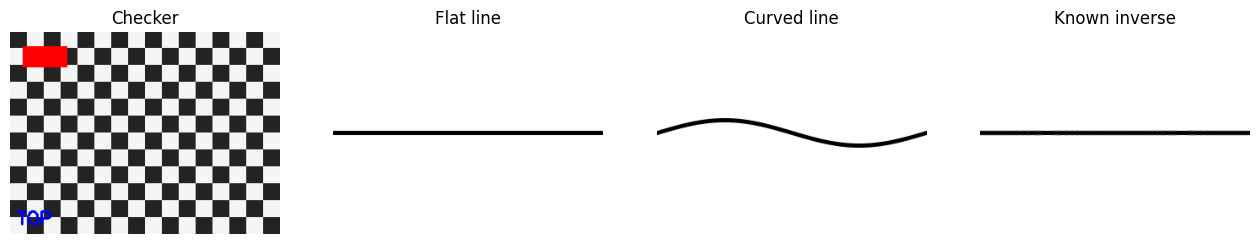

03.02: report updated, 1 companion table(s)


In [8]:
# 03.02 | Generate deterministic checkerboard and curved-line documents
H, W = 240, 320
xx = np.arange(W, dtype=np.float32)[None, :]
yy = np.arange(H, dtype=np.float32)[:, None]
checker = (((np.floor(xx / 20) + np.floor(yy / 20)) % 2) * 210 + 35).astype(np.uint8)
checker = cv2.cvtColor(checker, cv2.COLOR_GRAY2RGB)
cv2.rectangle(checker, (15, 18), (67, 42), (255, 0, 0), thickness=-1)
cv2.putText(checker, 'TOP', (8, H - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
line_doc = np.full((H, W, 3), 255, dtype=np.uint8)
cv2.line(line_doc, (0, 120), (W - 1, 120), (0, 0, 0), thickness=3)
amp = 15.0
map_x = np.broadcast_to(xx, (H, W)).copy()
map_y = np.broadcast_to(yy, (H, W)).copy() + amp * np.sin(2 * np.pi * map_x / (W - 1))
curved_doc = cv2.remap(line_doc, map_x, map_y, interpolation=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))
corrected_curve = cv2.remap(curved_doc, map_x, 2 * np.broadcast_to(yy, (H, W)) - map_y,
                           interpolation=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))
for name, img in [('checker', checker), ('flat_line', line_doc), ('curved_line', curved_doc), ('corrected_curve', corrected_curve)] :
    target = RUN_DIR / 'synthetic' / f'{name}.png'
    cv2.imwrite(str(target), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    register(target, '03.02', 'synthetic_image')

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, img) in zip(axs, [('Checker', checker), ('Flat line', line_doc), ('Curved line', curved_doc), ('Known inverse', corrected_curve)]) :
    ax.imshow(img); ax.set_title(title); ax.axis('off')
companion = pd.DataFrame([{'panel': n, 'image_width': im.shape[1], 'image_height': im.shape[0],
                           'warp_amplitude_px': amp if n in ('curved_line', 'known_inverse') else 0,
                           'kind': 'synthetic known geometry'} for n, im in
                          [('checker', checker), ('flat_line', line_doc), ('curved_line', curved_doc), ('known_inverse', corrected_curve)]])
figure_with_data('03.02', 'Synthetic coordinate-test images', fig, companion,
                 'The sinusoidal sampling displacement has amplitude 15 px and returns to zero at both horizontal ends. '
                 'The inverse uses a known map; this is not an estimated nonrigid method.')


In [9]:
# 03.03 | Test identity mapping, axes and normalization
def identity_grid(width : int, height : int, device='cpu') :
    xs = torch.linspace(-1, 1, width, device=device)
    ys = torch.linspace(-1, 1, height, device=device)
    Y, X = torch.meshgrid(ys, xs, indexing='ij')
    return torch.stack([X, Y], dim=-1).unsqueeze(0)


def grid_sample_np(image : np.ndarray, grid : torch.Tensor, mode='bilinear') :
    ten = torch.from_numpy(image.transpose(2, 0, 1).copy()).unsqueeze(0).float() / 255.0
    return (F.grid_sample(ten, grid.cpu(), mode=mode, padding_mode='zeros', align_corners=True)[0]
            .permute(1, 2, 0).numpy() * 255.0)

ident = identity_grid(W, H)
exact = grid_sample_np(checker, ident)
identity_max = float(np.abs(exact - checker).max())
wrong_grid = ident.flip(-1)
wrong = grid_sample_np(checker, wrong_grid)
wrong_mae = float(np.abs(wrong - checker).mean())
translation = identity_grid(W, H)
translation[..., 0] += 2 * 8 / (W - 1)
pixel_diff_x = (translation[..., 0] - ident[..., 0]) * (W - 1) / 2
translation_err = float((pixel_diff_x - 8).abs().max())
invalid = torch.full_like(ident, float('nan'))
invalid_detected = not bool(torch.isfinite(invalid).all())
TESTS_A = [
    {'test': 'identity grid', 'measurement': identity_max, 'threshold': 0.01, 'status': 'PASS' if identity_max < 0.01 else 'FAIL'},
    {'test': 'x/y swap negative control', 'measurement': wrong_mae, 'threshold': 10.0, 'status': 'PASS' if wrong_mae > 10 else 'FAIL'},
    {'test': '8px coordinate translation', 'measurement': translation_err, 'threshold': 0.0001, 'status': 'PASS' if translation_err < 1e-4 else 'FAIL'},
    {'test': 'non-finite grid detection', 'measurement': int(invalid_detected), 'threshold': 1, 'status': 'PASS' if invalid_detected else 'FAIL'},
]
GRID_TESTS = pd.DataFrame(TESTS_A)
print(GRID_TESTS.to_string(index=False))
publish('03.03', 'Coordinate and identity checks',
        'Identity uses `align_corners=True`; swapped axes are an intentional negative control. Thresholds are for float32 image and coordinate tests.',
        {'Grid tests': GRID_TESTS})
if (GRID_TESTS.status.ne('PASS').any()) :
    raise AssertionError('Synthetic grid correctness gate failed; do not proceed to pretrained inference.')


                      test  measurement  threshold status
             identity grid     0.004669     0.0100   PASS
 x/y swap negative control   104.577675    10.0000   PASS
8px coordinate translation     0.000005     0.0001   PASS
 non-finite grid detection     1.000000     1.0000   PASS
03.03: report updated, 1 companion table(s)


In [10]:
# 03.04 | Test known projective homography and curved-page limitation
source_corners = np.float32([[30, 20], [W - 25, 40], [W - 12, H - 22], [16, H - 30]])
dest_corners = np.float32([[0, 0], [W - 1, 0], [W - 1, H - 1], [0, H - 1]])
H_rectify = cv2.getPerspectiveTransform(source_corners, dest_corners)
projected = cv2.perspectiveTransform(source_corners[None, :, :], H_rectify)[0]
corner_error = float(np.linalg.norm(projected - dest_corners, axis=1).mean())

# Construct perspective-distorted checker through the exact inverse homography.
perspective = cv2.warpPerspective(checker, np.linalg.inv(H_rectify), (W, H), flags=cv2.INTER_LINEAR)
restored = cv2.warpPerspective(perspective, H_rectify, (W, H), flags=cv2.INTER_LINEAR)
center_error = float(np.abs(restored[50:-50, 50:-50].astype(float) - checker[50:-50, 50:-50].astype(float)).mean())


def line_center_std(rgb : np.ndarray) :
    centers = []
    for col in range(15, rgb.shape[1] - 15) :
        ys = np.flatnonzero(np.mean(rgb[:, col].astype(float), axis=1) < 128)
        if (len(ys) > 0) :
            centers.append(float(np.mean(ys)))
    return float(np.std(centers)) if centers else float('nan')

curve_raw_std = line_center_std(curved_doc)
curve_homog_std = line_center_std(cv2.warpPerspective(curved_doc, np.eye(3), (W, H)))
curve_inverse_std = line_center_std(corrected_curve)
PROJECTIVE_TESTS = pd.DataFrame([
    {'test': 'four-corner reprojection', 'value': corner_error, 'units': 'px', 'status': 'PASS' if corner_error < 1e-3 else 'FAIL'},
    {'test': 'perspective roundtrip center region', 'value': center_error, 'units': 'pixel MAE', 'status': 'DIAGNOSTIC'},
    {'test': 'sinusoidal curved line before correction', 'value': curve_raw_std, 'units': 'y std px', 'status': 'DIAGNOSTIC'},
    {'test': 'curved line under identity corner homography', 'value': curve_homog_std, 'units': 'y std px', 'status': 'DIAGNOSTIC'},
    {'test': 'known inverse-map curved line', 'value': curve_inverse_std, 'units': 'y std px', 'status': 'PASS' if curve_inverse_std < curve_raw_std else 'FAIL'},
])
print(PROJECTIVE_TESTS.to_string(index=False))
publish('03.04', 'Projective mapping and curvature limitation',
        'Projective corner agreement and pixel interpolation error are separate. The sinusoidal document has zero boundary displacement at left/right ends, so a boundary-fitted planar homography cannot recover its internal curvature. '
        'Known inverse deformation is an oracle, not an automatic method.', {'Synthetic geometry': PROJECTIVE_TESTS})
if (PROJECTIVE_TESTS.status.eq('FAIL').any()) :
    raise AssertionError('Projective/curvature correctness tests failed.')


                                        test        value     units     status
                    four-corner reprojection 3.800202e-15        px       PASS
         perspective roundtrip center region 8.424513e+00 pixel MAE DIAGNOSTIC
    sinusoidal curved line before correction 1.112407e+01  y std px DIAGNOSTIC
curved line under identity corner homography 1.112407e+01  y std px DIAGNOSTIC
               known inverse-map curved line 0.000000e+00  y std px       PASS
03.04: report updated, 1 companion table(s)


In [11]:
# 03.05 | Measure interpolation/padding behavior on known grids
INTERPOLATION_ROWS = []
for interp in ['nearest', 'bilinear', 'bicubic'] :
    recon = grid_sample_np(checker, ident, interp)
    INTERPOLATION_ROWS.append({'mode': interp, 'identity_mae': float(np.abs(recon - checker).mean()),
                               'identity_max': float(np.abs(recon - checker).max()),
                               'shape': str(recon.shape)})
# Zero padding should return black when all sampling locations lie outside [-1, 1].
outside = torch.full_like(ident, 3.0)
outside_pixel = grid_sample_np(checker, outside)
INTERPOLATION_ROWS.append({'mode': 'zero_padding_out_of_bounds', 'identity_mae': float(np.abs(outside_pixel).mean()),
                           'identity_max': float(np.abs(outside_pixel).max()), 'shape': str(outside_pixel.shape)})
INTERP_TESTS = pd.DataFrame(INTERPOLATION_ROWS)
print(INTERP_TESTS.to_string(index=False))
publish('03.05', 'Sampling and interpolation checks',
        'The same identity coordinates are used for all samplers. Float differences are numerical details, not proof of a quality advantage. '
        'All-outside sampling tests explicit zero padding.', {'Interpolation checks': INTERP_TESTS})
if (INTERP_TESTS.loc[INTERP_TESTS['mode'] == 'zero_padding_out_of_bounds', 'identity_max'].iloc[0] != 0) :
    raise AssertionError('Out-of-bounds zero-padding control failed')


                      mode  identity_mae  identity_max         shape
                   nearest      0.000000      0.000000 (240, 320, 3)
                  bilinear      0.000050      0.004669 (240, 320, 3)
                   bicubic      0.000081      0.004810 (240, 320, 3)
zero_padding_out_of_bounds      0.000000      0.000000 (240, 320, 3)
03.05: report updated, 1 companion table(s)


### 04.01 Official source and checkpoint identity

The pretrained baseline uses [`model.py`](https://github.com/tanguymagne/UVDoc/blob/main/model.py), [`utils.py`](https://github.com/tanguymagne/UVDoc/blob/main/utils.py), and the released `model/best_model.pkl` without changing model weights. A clean checkout is made under `/content/uvdoc_reference_source`, outside the team's Git repository. The exact revision and SHA-256 checkpoint hash are recorded and checked against any previous run with the same run ID.

**Warning:** Model checkpoints are executable Python deserialization data in some environments. This notebook loads only the official public checkpoint and attempts safe `weights_only=True` deserialization. Do not use unknown third-party checkpoints.


In [12]:
# 04.02 | Clone official UVDoc snapshot outside team repository
import subprocess

if (not (OFFICIAL_DIR / 'model.py').is_file()) :
    if (OFFICIAL_DIR.exists()) :
        raise RuntimeError(f'{OFFICIAL_DIR} exists but does not contain model.py; inspect manually before reuse.')
    subprocess.run(['git', 'clone', '--depth', '1', OFFICIAL_URL, str(OFFICIAL_DIR)], check=True)
if (PINNED_UVDOC_REVISION) :
    current_rev = subprocess.check_output(['git', '-C', str(OFFICIAL_DIR), 'rev-parse', 'HEAD'], text=True).strip()
    if (not current_rev.startswith(PINNED_UVDOC_REVISION)) :
        raise RuntimeError(f'Cloned {current_rev}, not requested pinned revision {PINNED_UVDOC_REVISION}. '
                           'Use a checkout of the requested revision and rerun; do not silently switch revisions.')
SOURCE_REVISION = subprocess.check_output(['git', '-C', str(OFFICIAL_DIR), 'rev-parse', 'HEAD'], text=True).strip()
OFFICIAL_CHECKPOINT = OFFICIAL_DIR / 'model/best_model.pkl'
if (not OFFICIAL_CHECKPOINT.is_file()) :
    raise FileNotFoundError(f'Official checkpoint missing: {OFFICIAL_CHECKPOINT}')
if (OFFICIAL_CHECKPOINT.stat().st_size < 1024 * 1024) :
    raise RuntimeError('Checkpoint is suspiciously small, possibly a Git LFS pointer rather than model weights.')
ckpt_hash = hashlib.sha256()
with OFFICIAL_CHECKPOINT.open('rb') as f :
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b'') :
        ckpt_hash.update(chunk)
CHECKPOINT_SHA256 = ckpt_hash.hexdigest()
REFERENCE_ASSETS = {'source_url': OFFICIAL_URL, 'source_revision': SOURCE_REVISION,
                    'checkpoint': 'model/best_model.pkl', 'checkpoint_bytes': OFFICIAL_CHECKPOINT.stat().st_size,
                    'checkpoint_sha256': CHECKPOINT_SHA256}
assets_path = RUN_DIR / 'reference_assets.json'
if (assets_path.is_file()) :
    prior_assets = json.loads(assets_path.read_text(encoding='utf-8'))
    if (prior_assets != REFERENCE_ASSETS) :
        raise RuntimeError('Reference source/checkpoint changed for the same RUN_ID. Change RUN_LABEL to avoid mixed outputs.')
assets_path.write_text(json.dumps(REFERENCE_ASSETS, indent=2), encoding='utf-8')
register(assets_path, '04.02', 'source_identity')
print(json.dumps(REFERENCE_ASSETS, indent=2))
publish('04.02', 'Reference model identity',
        f'Official UVDoc revision: `{SOURCE_REVISION}`; pretrained checkpoint SHA-256: `{CHECKPOINT_SHA256}`. '
        'Repository cloned under temporary /content, not into the team project.',
        {'Reference assets': pd.DataFrame([REFERENCE_ASSETS])})


{
  "source_url": "https://github.com/tanguymagne/UVDoc.git",
  "source_revision": "4c9b82b537057aff2526e6dd118a847cdd072e82",
  "checkpoint": "model/best_model.pkl",
  "checkpoint_bytes": 32158393,
  "checkpoint_sha256": "7e90861b8a516eb4bc51f84bd889cb77275743d2d1d3ca8091951ec9f2b7da23"
}
04.02: report updated, 1 companion table(s)


In [13]:
# 04.03 | Load trusted checkpoint and verify parameter keys
import importlib.util

if (str(OFFICIAL_DIR) not in sys.path) :
    sys.path.insert(0, str(OFFICIAL_DIR))
from model import UVDocnet
import utils as official_utils

MODEL = UVDocnet(num_filter=32, kernel_size=5)
try :
    checkpoint = torch.load(OFFICIAL_CHECKPOINT, map_location='cpu', weights_only=True)
except Exception as exc :
    raise RuntimeError('Safe checkpoint loading failed. Inspect the official checkpoint and PyTorch compatibility '
                       'before using any less restrictive deserialization.') from exc
if (not isinstance(checkpoint, dict) or 'model_state' not in checkpoint) :
    raise RuntimeError(f'Expected model_state in checkpoint, found keys {list(checkpoint) if isinstance(checkpoint, dict) else type(checkpoint)}')
MODEL.load_state_dict(checkpoint['model_state'], strict=True)
MODEL = MODEL.to(DEVICE).float().eval()
N_PARAMS = sum(param.numel() for param in MODEL.parameters())
model_info = pd.DataFrame([{'architecture': 'UVDocnet(num_filter=32, kernel_size=5)',
                            'parameter_count': N_PARAMS, 'checkpoint_mb': OFFICIAL_CHECKPOINT.stat().st_size / 1e6,
                            'input_width': official_utils.IMG_SIZE[0], 'input_height': official_utils.IMG_SIZE[1],
                            'official_grid_size': str(official_utils.GRID_SIZE), 'dtype': 'float32'}])
print(model_info.to_string(index=False))
publish('04.03', 'Official pretrained model loaded',
        'Loaded strict state_dict from `model_state` on NVIDIA L4. Model weights remain unchanged.',
        {'Model properties': model_info})


                          architecture  parameter_count  checkpoint_mb  input_width  input_height official_grid_size   dtype
UVDocnet(num_filter=32, kernel_size=5)          8003463      32.158393          488           712           [45, 31] float32
04.03: report updated, 1 companion table(s)


In [14]:
# 04.04 | Validate 2D and 3D output tensor shapes
with torch.inference_mode() :
    zero_input = torch.zeros((1, 3, official_utils.IMG_SIZE[1], official_utils.IMG_SIZE[0]), device=DEVICE)
    g2_zero, g3_zero = MODEL(zero_input)
expected_spatial = (official_utils.GRID_SIZE[0], official_utils.GRID_SIZE[1])  # H=45, W=31
shape_ok = tuple(g2_zero.shape) == (1, 2, *expected_spatial) and tuple(g3_zero.shape) == (1, 3, *expected_spatial)
finite_ok = bool(torch.isfinite(g2_zero).all() and torch.isfinite(g3_zero).all())
MODEL_SMOKE = pd.DataFrame([{'input_shape': str(tuple(zero_input.shape)), 'grid2d_shape': str(tuple(g2_zero.shape)),
                             'grid3d_shape': str(tuple(g3_zero.shape)), 'all_finite': finite_ok,
                             'status': 'PASS' if shape_ok and finite_ok else 'FAIL'}])
print(MODEL_SMOKE.to_string(index=False))
publish('04.04', 'Model forward smoke test',
        'A zero tensor checks executable architecture and output shape only, not document rectification quality.',
        {'Forward shape': MODEL_SMOKE})
if (not shape_ok or not finite_ok) :
    raise RuntimeError('Official UVDoc output shape/finite test failed')
del zero_input, g2_zero, g3_zero


     input_shape   grid2d_shape   grid3d_shape  all_finite status
(1, 3, 712, 488) (1, 2, 45, 31) (1, 3, 45, 31)        True   PASS
04.04: report updated, 1 companion table(s)


### 05.01 Grid annotations and EDA consistency

The raw HDF5 grid arrays are stored differently from their appearance after the official UVDoc training loader: 2D loader coordinates have shape `(2, 89, 61)` and remain **pixel coordinates** until tight cropping/normalization. The neural output has shape `(2, 45, 31)` and encodes a normalized backward sampling map. No raw-pixel minus normalized-grid subtraction is permitted.

The pilot reproduces EDA-style overlays and matches numeric EDA corner records when available. The official training loader also uses random tight cropping, so direct predicted-versus-training-ground-truth L2 comparison is **not** valid here without matching the loader's sample-specific crop and normalization.


In [15]:
# 05.02 | Read selected 2D/3D annotations and original HDF5 shapes
def load_grid_2d(path : Path) :
    with h5py.File(path, 'r') as file :
        if ('grid2d' not in file) :
            raise KeyError(f'Missing grid2d in {path}')
        raw_shape = tuple(file['grid2d'].shape)
        data = np.array(file['grid2d'][:].T.transpose(2, 0, 1), dtype=np.float64)
    return data, raw_shape


def load_grid_3d(path : Path) :
    with h5py.File(path, 'r') as file :
        if ('grid3d' not in file) :
            raise KeyError(f'Missing grid3d in {path}')
        raw_shape = tuple(file['grid3d'].shape)
        data = np.array(file['grid3d'][:].T, dtype=np.float64)
    return data, raw_shape


GRID_REGISTRY = {}
GRID_ROWS = []
for r in PILOT[PILOT.dataset.str.startswith('UVDoc')].itertuples(index=False) :
    p2 = resolve_path(r.grid2d_path)
    p3 = resolve_path(r.grid3d_path)
    if (not p2.is_file() or not p3.is_file()) :
        GRID_ROWS.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'sample_id': r.sample_id,
                          'status': 'UNAVAILABLE', 'reason': 'grid file not staged'})
        continue
    g2, raw2 = load_grid_2d(p2)
    g3, raw3 = load_grid_3d(p3)
    if (g2.shape != (2, 89, 61) or g3.shape != (89, 61, 3)) :
        raise ValueError(f'Unexpected loader grids for {r.sample_key}: {g2.shape}, {g3.shape}')
    if (not np.isfinite(g2).all() or not np.isfinite(g3).all()) :
        raise ValueError(f'Non-finite annotation grid: {r.sample_key}')
    GRID_REGISTRY[r.sample_key] = (g2, g3)
    GRID_ROWS.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'sample_id': r.sample_id,
                      'geom_name': r.geom_name, 'raw2d': str(raw2), 'loader2d': str(g2.shape),
                      'raw3d': str(raw3), 'loader3d': str(g3.shape),
                      'x_min': float(g2[0].min()), 'x_max': float(g2[0].max()),
                      'y_min': float(g2[1].min()), 'y_max': float(g2[1].max()),
                      'z_min': float(g3[:, :, 2].min()), 'z_max': float(g3[:, :, 2].max()),
                      'status': 'PASS', 'reason': ''})
GRID_AUDIT = pd.DataFrame(GRID_ROWS)
print(GRID_AUDIT.to_string(index=False))
publish('05.02', 'Released grid structures and ranges',
        'Grid values are released pixel-space 2D coordinates and uncalibrated 3D values; the 2D neural prediction is not directly comparable to these raw arrays.',
        {'Grid annotation audit': GRID_AUDIT})


                    sample_key         dataset sample_id      geom_name       raw2d    loader2d       raw3d    loader3d     x_min      x_max      y_min       y_max     z_min    z_max status reason
    UVDoc_Final_rendered_05930     UVDoc Final     05930 04_00022_1_1_0 (2, 61, 89) (2, 89, 61) (3, 61, 89) (89, 61, 3) 22.223379 470.151851  90.933213  655.302048 -0.143499 0.138399   PASS       
    UVDoc_Final_rendered_06349     UVDoc Final     06349 06_00053_1_0_1 (2, 61, 89) (2, 89, 61) (3, 61, 89) (89, 61, 3) 59.644443 426.096304 110.685280  660.497465 -0.147586 0.146404   PASS       
    UVDoc_Final_rendered_14254     UVDoc Final     14254 06_00013_1_1_0 (2, 61, 89) (2, 89, 61) (3, 61, 89) (89, 61, 3) 26.382021 459.533332 165.350259  664.563475 -0.143838 0.121215   PASS       
UVDoc_Benchmark_rendered_00010 UVDoc Benchmark     00010 09_00013_1_0_0 (2, 61, 89) (2, 89, 61) (3, 61, 89) (89, 61, 3)  6.999996 860.000019  19.183368 1175.999942 -0.143184 0.144468   PASS       
UVDoc_Benchmark

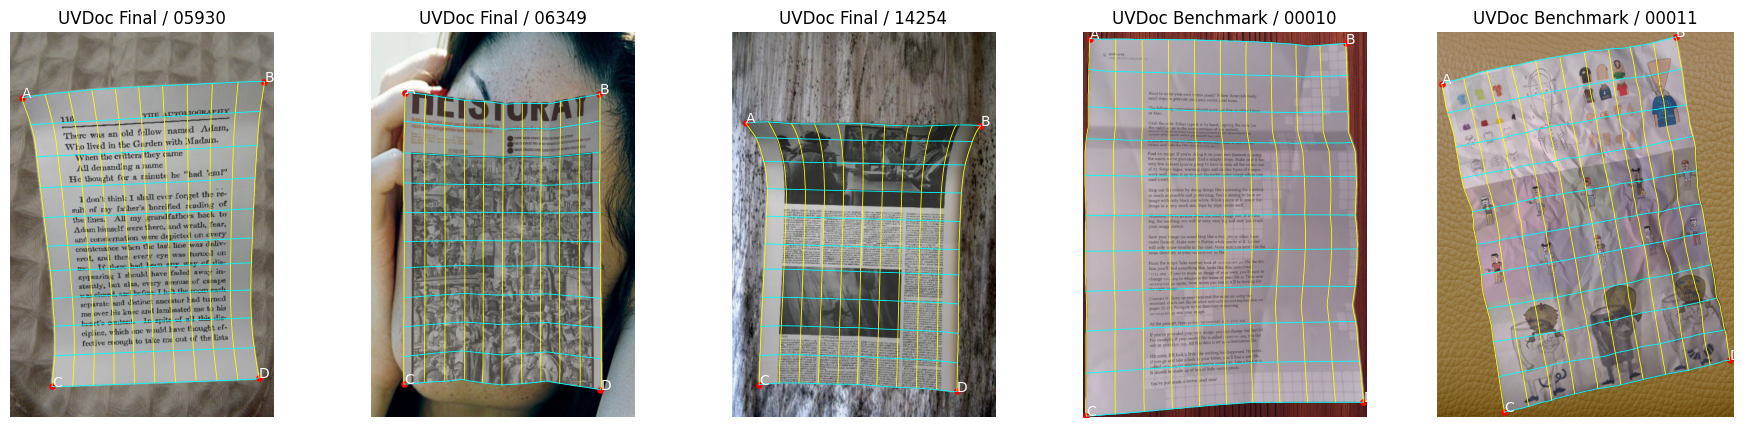

05.03: report updated, 1 companion table(s)


In [16]:
# 05.03 | Generate 2D grid overlays with coordinate companions
GRID_CORNER_ROWS = []
preview = [r for r in PILOT.itertuples(index=False) if r.sample_key in GRID_REGISTRY][:5]
if (preview) :
    fig, axs = plt.subplots(1, len(preview), figsize=(4.5 * len(preview), 5))
    axs = np.atleast_1d(axs)
    for ax, r in zip(axs, preview) :
        rgb = decode_rgb(resolve_path(r.input_path))
        g2, _ = GRID_REGISTRY[r.sample_key]
        ax.imshow(rgb)
        for ix in np.linspace(0, g2.shape[2] - 1, 11, dtype=int) :
            ax.plot(g2[0, :, ix], g2[1, :, ix], color='yellow', linewidth=0.6)
        for iy in np.linspace(0, g2.shape[1] - 1, 11, dtype=int) :
            ax.plot(g2[0, iy, :], g2[1, iy, :], color='cyan', linewidth=0.6)
        for corner, iy, ix in [('A', 0, 0), ('B', 0, -1), ('C', -1, 0), ('D', -1, -1)] :
            x, y = g2[0, iy, ix], g2[1, iy, ix]
            ax.scatter([x], [y], c='red', s=14); ax.text(float(x), float(y), corner, color='white')
            GRID_CORNER_ROWS.append({'dataset': r.dataset, 'sample_id': r.sample_id,
                                     'sample_key': r.sample_key, 'corner': corner,
                                     'x_px': float(x), 'y_px': float(y),
                                     'image_width': rgb.shape[1], 'image_height': rgb.shape[0]})
        ax.set_title(f'{r.dataset} / {r.sample_id}'); ax.axis('off')
    GRID_CORNERS = pd.DataFrame(GRID_CORNER_ROWS)
    figure_with_data('05.03', 'Image-space UVDoc annotation overlays', fig, GRID_CORNERS,
                     'A/B/C/D are grid-index corners, not manually verified physical page corners. '
                     'Each plotted point is in the original decoded image pixel coordinate system.')
else :
    GRID_CORNERS = pd.DataFrame()
    publish('05.03', 'Image-space UVDoc annotation overlays',
            'UNAVAILABLE: No UVDoc annotation file found. Restore benchmark data or stage the selected Final files.',
            {'Corner table': GRID_CORNERS})


In [17]:
# 05.04 | Compare grid corners with the saved November 20 EDA
eda_corners = META_ROOT / '05_03_figure_data.csv'
EDA_MATCH_ROWS = []
if (eda_corners.is_file() and not GRID_CORNERS.empty) :
    expected_corners = pd.read_csv(eda_corners, dtype={'sample_id': str}, keep_default_na=False)
    merged = GRID_CORNERS.merge(expected_corners, on=['dataset', 'sample_id', 'corner'], how='inner', suffixes=('_pilot', '_eda'))
    for row in merged.itertuples(index=False) :
        delta = float(np.hypot(row.x_px_pilot - row.x_px_eda, row.y_px_pilot - row.y_px_eda))
        EDA_MATCH_ROWS.append({'dataset': row.dataset, 'sample_id': row.sample_id, 'corner': row.corner,
                               'error_px': delta, 'status': 'PASS' if delta < 0.01 else 'FAIL'})
    if (not len(merged)) :
        EDA_MATCH_ROWS.append({'dataset': '', 'sample_id': '', 'corner': '', 'error_px': float('nan'), 'status': 'UNAVAILABLE'})
else :
    EDA_MATCH_ROWS.append({'dataset': '', 'sample_id': '', 'corner': '', 'error_px': float('nan'), 'status': 'UNAVAILABLE'})
EDA_MATCH = pd.DataFrame(EDA_MATCH_ROWS)
print(EDA_MATCH.to_string(index=False))
publish('05.04', 'EDA grid-coordinate consistency',
        'Numerical comparison against the exact EDA `05_03_figure_data.csv` corner records, where overlapping samples are available. '
        'No raw-to-predicted grid L2 metric is claimed because tight crop/normalization differs.',
        {'EDA corner differences': EDA_MATCH})
if (EDA_MATCH.status.eq('FAIL').any()) :
    raise AssertionError('UVDoc annotation transformation disagrees with the saved EDA corners')


        dataset sample_id corner     error_px status
    UVDoc Final     05930      A 0.000000e+00   PASS
    UVDoc Final     05930      B 5.684342e-14   PASS
    UVDoc Final     05930      C 0.000000e+00   PASS
    UVDoc Final     05930      D 5.684342e-14   PASS
    UVDoc Final     06349      A 0.000000e+00   PASS
    UVDoc Final     06349      B 5.684342e-14   PASS
    UVDoc Final     06349      C 0.000000e+00   PASS
    UVDoc Final     06349      D 5.684342e-14   PASS
    UVDoc Final     14254      A 0.000000e+00   PASS
    UVDoc Final     14254      B 0.000000e+00   PASS
    UVDoc Final     14254      C 7.105427e-15   PASS
    UVDoc Final     14254      D 0.000000e+00   PASS
UVDoc Benchmark     00010      A 0.000000e+00   PASS
UVDoc Benchmark     00010      B 0.000000e+00   PASS
UVDoc Benchmark     00010      C 0.000000e+00   PASS
UVDoc Benchmark     00010      D 0.000000e+00   PASS
05.04: report updated, 1 companion table(s)


### 06.01 Reference-faithful UVDoc inference

The model sees the RGB image resized to **488 × 712 (width × height)**. The original decoded RGB image is retained and rectified at its native resolution by the official `bilinear_unwarping` function with `align_corners=True`. No preprocessing is inserted in `uvdoc_official`.

One full decoded image is processed at a time on the L4. Save the normalized coarse 2D map, 3D output, official benchmark-compatible backward-map MAT for UVDoc Benchmark, source dimensions, runtime, and full-resolution rectified PNG. Save the baseline separately from all experimental variants. Stop and diagnose an unexpected reference-equivalence failure.


In [18]:
# 06.02 | Define exact official preprocessing, warping and save helpers
def official_input(image_uint8 : np.ndarray) :
    image_float = image_uint8.astype(np.float32) / 255.0
    resized = cv2.resize(image_float, tuple(official_utils.IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    return torch.from_numpy(resized.transpose(2, 0, 1).copy()).unsqueeze(0).to(DEVICE), image_float


def save_rgb(image_uint8 : np.ndarray, path : Path) :
    if (image_uint8.dtype != np.uint8 or image_uint8.ndim != 3 or image_uint8.shape[2] != 3) :
        raise ValueError(f'Expected HxWx3 uint8 RGB, got {image_uint8.shape}, {image_uint8.dtype}')
    path.parent.mkdir(parents=True, exist_ok=True)
    if (not cv2.imwrite(str(path), cv2.cvtColor(image_uint8, cv2.COLOR_RGB2BGR))) :
        raise OSError(f'OpenCV failed to save {path}')


def official_warp(image_float : np.ndarray, grid2d : torch.Tensor) :
    image_tensor = torch.from_numpy(image_float.transpose(2, 0, 1).copy()).unsqueeze(0).to(DEVICE)
    return official_utils.bilinear_unwarping(image_tensor, grid2d, (image_float.shape[1], image_float.shape[0]))


def as_official_png(warped_tensor : torch.Tensor) :
    # Reference demo casts directly to uint8 after multiplying by 255 (truncation, not rounding).
    return (warped_tensor[0].detach().cpu().numpy().transpose(1, 2, 0) * 255).astype(np.uint8)


def cuda_sync() :
    if (DEVICE.type == 'cuda') :
        torch.cuda.synchronize()


def infer_sample(r, variant='uvdoc_official', override_network_rgb=None, warp_mode='bilinear') :
    if (not resolve_path(r.input_path).is_file()) :
        raise FileNotFoundError(f'Input unavailable: {r.input_path}')
    start = perf_counter()
    source = decode_rgb(resolve_path(r.input_path))
    network_rgb = source if override_network_rgb is None else override_network_rgb
    inp, source_float = official_input(network_rgb)
    decode_and_prepare_ms = (perf_counter() - start) * 1000
    cuda_sync(); t_forward = perf_counter()
    with torch.inference_mode() :
        predicted_2d, predicted_3d = MODEL(inp)
        cuda_sync()
        forward_ms = (perf_counter() - t_forward) * 1000
        cuda_sync(); t_warp = perf_counter()
        if (warp_mode == 'bilinear') :
            output_tensor = official_warp(source_float, predicted_2d)
        elif (warp_mode == 'bicubic') :
            image_tensor = torch.from_numpy(source_float.transpose(2, 0, 1).copy()).unsqueeze(0).to(DEVICE)
            full = F.interpolate(predicted_2d, size=(source.shape[0], source.shape[1]), mode='bilinear', align_corners=True)
            output_tensor = F.grid_sample(image_tensor, full.permute(0, 2, 3, 1), mode='bicubic', padding_mode='zeros', align_corners=True)
        else :
            raise ValueError(f'Unexpected warp mode: {warp_mode}')
        cuda_sync()
    warp_ms = (perf_counter() - t_warp) * 1000
    result = as_official_png(output_tensor)
    if (warp_mode == 'bicubic') :
        # Avoid uint8 wraparound from bicubic overshoots; report this as a different sampler.
        result = (output_tensor[0].clamp(0, 1).detach().cpu().numpy().transpose(1, 2, 0) * 255).astype(np.uint8)
    return {'rgb': source, 'result': result, 'grid2d': predicted_2d[0].detach().cpu().numpy(),
            'grid3d': predicted_3d[0].detach().cpu().numpy(),
            'decode_prepare_ms': decode_and_prepare_ms, 'forward_ms': forward_ms, 'warp_ms': warp_ms,
            'output_width': result.shape[1], 'output_height': result.shape[0],
            'max_gpu_memory_mb': torch.cuda.max_memory_allocated() / 1e6}


print('Official inference helpers ready; no image has been processed yet.')


Official inference helpers ready; no image has been processed yet.


In [19]:
# 06.03 | Run single annotated benchmark smoke test and save its maps
bench_first = next(r for r in PILOT.itertuples(index=False) if r.dataset == 'UVDoc Benchmark')
torch.cuda.reset_peak_memory_stats()
SMOKE_RESULT = infer_sample(bench_first)
assert SMOKE_RESULT['result'].shape == SMOKE_RESULT['rgb'].shape
assert np.isfinite(SMOKE_RESULT['grid2d']).all() and np.isfinite(SMOKE_RESULT['grid3d']).all()
smoke_out = RUN_DIR / 'predictions/uvdoc_official' / f'{bench_first.sample_key}.png'
save_rgb(SMOKE_RESULT['result'], smoke_out)
register(smoke_out, '06.03', 'pilot_smoke_output')
smoke_grid = RUN_DIR / 'grids' / f'{bench_first.sample_key}.npz'
np.savez_compressed(smoke_grid, grid2d=SMOKE_RESULT['grid2d'], grid3d=SMOKE_RESULT['grid3d'])
register(smoke_grid, '06.03', 'predicted_coarse_grids')
smoke_table = pd.DataFrame([{'sample_key': bench_first.sample_key, 'source_width': SMOKE_RESULT['rgb'].shape[1],
                             'source_height': SMOKE_RESULT['rgb'].shape[0], 'grid2d_shape': str(SMOKE_RESULT['grid2d'].shape),
                             'grid3d_shape': str(SMOKE_RESULT['grid3d'].shape),
                             'grid_x_min': float(SMOKE_RESULT['grid2d'][0].min()),
                             'grid_x_max': float(SMOKE_RESULT['grid2d'][0].max()),
                             'grid_y_min': float(SMOKE_RESULT['grid2d'][1].min()),
                             'grid_y_max': float(SMOKE_RESULT['grid2d'][1].max()),
                             'forward_ms': SMOKE_RESULT['forward_ms'], 'warp_ms': SMOKE_RESULT['warp_ms'],
                             'status': 'PASS'}])
print(smoke_table.to_string(index=False))
publish('06.03', 'First real pretrained inference',
        f'Official baseline rectified image: `{rel(smoke_out)}`. Saved both the coarse 2D and 3D predictions. '
        'Output dimensions match the source (not the reference scan).', {'Single-image inference': smoke_table})


                    sample_key  source_width  source_height grid2d_shape grid3d_shape  grid_x_min  grid_x_max  grid_y_min  grid_y_max  forward_ms   warp_ms status
UVDoc_Benchmark_rendered_00010           869           1180  (2, 45, 31)  (3, 45, 31)   -0.973972    0.974004   -0.957917    0.979989     8.25385 35.764592   PASS
06.03: report updated, 1 companion table(s)


In [20]:
# 06.04 | Infer all fixed pilot images and save per-sample results
BASELINE_ROWS = []
for r in tqdm(PILOT.itertuples(index=False), total=len(PILOT), desc='UVDoc float32 baseline') :
    if (not r.input_exists) :
        BASELINE_ROWS.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'variant': r.variant,
                              'sample_id': r.sample_id, 'method_id': 'uvdoc_official', 'status': 'UNAVAILABLE',
                              'reason': 'input missing'})
        continue
    # Baseline outputs are always regenerated on a normal rerun, preserving a single defined inference path.
    torch.cuda.reset_peak_memory_stats()
    t0 = perf_counter()
    res = infer_sample(r)
    path = RUN_DIR / 'predictions/uvdoc_official' / f'{r.sample_key}.png'
    save_rgb(res['result'], path)
    grid_path = RUN_DIR / 'grids' / f'{r.sample_key}.npz'
    np.savez_compressed(grid_path, grid2d=res['grid2d'], grid3d=res['grid3d'])
    register(path, '06.04', 'uvdoc_official_png'); register(grid_path, '06.04', 'coarse_grids')
    if (r.dataset == 'UVDoc Benchmark') :
        mat_path = RUN_DIR / 'predictions/bm' / f'{r.sample_id}.mat'
        hdf5storage.savemat(str(mat_path), {'bm': res['grid2d'].transpose(1, 2, 0)})
        register(mat_path, '06.04', 'official_bm_mat')
    BASELINE_ROWS.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'variant': r.variant,
                          'sample_id': r.sample_id, 'method_id': 'uvdoc_official',
                          'source_width': res['rgb'].shape[1], 'source_height': res['rgb'].shape[0],
                          'output_width': res['output_width'], 'output_height': res['output_height'],
                          'decode_prepare_ms': res['decode_prepare_ms'], 'forward_ms': res['forward_ms'],
                          'warp_ms': res['warp_ms'], 'total_ms': (perf_counter() - t0) * 1000,
                          'peak_vram_mb': res['max_gpu_memory_mb'], 'png_path': rel(path),
                          'grid2d_min': float(np.min(res['grid2d'])), 'grid2d_max': float(np.max(res['grid2d'])),
                          'status': 'PASS', 'reason': ''})
    del res
BASELINE = pd.DataFrame(BASELINE_ROWS)
BASELINE.to_csv(RUN_DIR / 'metrics/runtime.csv', index=False)
register(RUN_DIR / 'metrics/runtime.csv', '06.04', 'runtime_table')
print(BASELINE.groupby(['dataset', 'variant', 'status']).size().reset_index(name='images').to_string(index=False))
publish('06.04', 'Complete fixed-subset UVDoc inference',
        'All available selected images have an unmodified official float32 output, 2D/3D coarse grids, input variant, image dimensions, '
        'GPU timings and failure status. No image/reference metric is inferred from this table.', {'Per-sample baseline inference': BASELINE})


UVDoc float32 baseline:   0%|          | 0/23 [00:00<?, ?it/s]

        dataset  variant status  images
         DIR300     dist   PASS       4
        DocUNet     crop   PASS       8
        DocUNet original   PASS       2
UVDoc Benchmark rendered   PASS       6
    UVDoc Final rendered   PASS       3
06.04: report updated, 1 companion table(s)


In [21]:
# 06.05 | Compare against independently executed official demo path
import tempfile
import demo as official_demo

# This calls the released demo function itself using a temporary COPY, never the original dataset image.
reference_directory = Path('/content/uvdoc_reference_smoke')
reference_directory.mkdir(parents=True, exist_ok=True)
reference_input = reference_directory / 'reference_input.png'
reference_png = reference_directory / 'reference_input_unwarp.png'
source_image = decode_rgb(resolve_path(bench_first.input_path))
save_rgb(source_image, reference_input)
status, reference_note, max_abs, mean_abs = 'UNAVAILABLE', '', float('nan'), float('nan')
try :
    official_demo.unwarp_img(str(OFFICIAL_CHECKPOINT), str(reference_input), official_utils.IMG_SIZE)
    if (not reference_png.is_file()) :
        raise FileNotFoundError('Official demo did not produce its expected output')
    direct_reference = decode_rgb(reference_png)
    notebook_prediction = decode_rgb(RUN_DIR / 'predictions/uvdoc_official' / f'{bench_first.sample_key}.png')
    if (direct_reference.shape != notebook_prediction.shape) :
        raise ValueError(f'Output shape mismatch: reference {direct_reference.shape}, notebook {notebook_prediction.shape}')
    abs_delta = np.abs(direct_reference.astype(np.float32) - notebook_prediction.astype(np.float32))
    max_abs, mean_abs = float(abs_delta.max()), float(abs_delta.mean())
    status = 'PASS' if max_abs == 0 else 'FAIL'
    reference_note = 'Official demo output and pilot PNG are compared on identical decoded image contents and checkpoint.'
except (ImportError, RuntimeError, ValueError, FileNotFoundError, OSError) as exc :
    reference_note = f'{type(exc).__name__}: {exc}'
    status = 'FAIL' if STRICT_REFERENCE_EQUIVALENCE else 'UNAVAILABLE'
REFERENCE_EQ = pd.DataFrame([{'sample_key': bench_first.sample_key, 'reference': 'official demo.unwarp_img',
                              'max_abs_uint8': max_abs, 'mean_abs_uint8': mean_abs,
                              'status': status, 'detail': reference_note}])
print(REFERENCE_EQ.to_string(index=False))
publish('06.05', 'Official demo numerical equivalence gate',
        'Compared independent full official `demo.unwarp_img` execution from a temporary copied input with the notebook baseline PNG. '
        'The demo may require compatibility repair on recent PyTorch; an unverified mismatch is not silently accepted.',
        {'Official reference comparison': REFERENCE_EQ})
if (STRICT_REFERENCE_EQUIVALENCE and status != 'PASS') :
    raise RuntimeError(f'Official reference-equivalence gate failed: {reference_note}; max difference {max_abs}')


                    sample_key                reference  max_abs_uint8  mean_abs_uint8 status                                                                                              detail
UVDoc_Benchmark_rendered_00010 official demo.unwarp_img            0.0             0.0   PASS Official demo output and pilot PNG are compared on identical decoded image contents and checkpoint.
06.05: report updated, 1 companion table(s)


In [22]:
# 06.06 | Export grid diagnostics and inference timing summary
GRID_PRED_ROWS = []
for r in PILOT.itertuples(index=False) :
    f = RUN_DIR / 'grids' / f'{r.sample_key}.npz'
    if (not f.is_file()) :
        continue
    with np.load(f) as arrays :
        grid = arrays['grid2d']
    gx, gy = grid[0], grid[1]
    # `align_corners=True`: convert normalized sampling coordinates to original source pixels.
    imrow = BASELINE.loc[BASELINE.sample_key == r.sample_key].iloc[0]
    width, height = int(imrow.source_width), int(imrow.source_height)
    outside = (np.abs(gx) > 1) | (np.abs(gy) > 1)
    dx = np.diff(gx, axis=1) * (width - 1) / 2
    dy = np.diff(gy, axis=0) * (height - 1) / 2
    GRID_PRED_ROWS.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'coarse_height': grid.shape[1],
                           'coarse_width': grid.shape[2], 'normalized_x_min': float(gx.min()),
                           'normalized_x_max': float(gx.max()), 'normalized_y_min': float(gy.min()),
                           'normalized_y_max': float(gy.max()), 'outside_fraction': float(outside.mean()),
                           'median_horizontal_step_px': float(np.median(dx)),
                           'median_vertical_step_px': float(np.median(dy)), 'status': 'DIAGNOSTIC'})
PRED_GRID_AUDIT = pd.DataFrame(GRID_PRED_ROWS)
print(PRED_GRID_AUDIT.to_string(index=False))
publish('06.06', 'Predicted-grid descriptive diagnostics',
        'Predicted normalized grid distributions and source-pixel steps are descriptive; they are not EDA ground-truth grid errors. '
        'Runtime was saved separately with source and output dimensions in `metrics/runtime.csv`.',
        {'Predicted map diagnostics': PRED_GRID_AUDIT})


                    sample_key         dataset  coarse_height  coarse_width  normalized_x_min  normalized_x_max  normalized_y_min  normalized_y_max  outside_fraction  median_horizontal_step_px  median_vertical_step_px     status
    UVDoc_Final_rendered_05930     UVDoc Final             45            31         -0.910501          0.906795         -0.787068          0.836471               0.0                  12.725239                12.349207 DIAGNOSTIC
    UVDoc_Final_rendered_06349     UVDoc Final             45            31         -0.768695          0.753689         -0.721187          0.857235               0.0                  12.154868                11.995756 DIAGNOSTIC
    UVDoc_Final_rendered_14254     UVDoc Final             45            31         -0.861946          0.881187         -0.662829          0.860434               0.0                  12.136385                12.391464 DIAGNOSTIC
UVDoc_Benchmark_rendered_00010 UVDoc Benchmark             45            31         

### 07.01 Classical quadrilateral detection and homography

Use separate method labels: `homography_auto` estimates a quadrilateral via classical edges/contours, `homography_manual` requires **explicit reviewed corner coordinates**, and `homography_grid_oracle` uses ground-truth UVDoc geometry only as a controlled annotation-assisted diagnostic. Never call automatic corners "manual". Cropped photographs often exclude physical document boundaries; detection may validly fail.

Default proposal: 5×5 Gaussian blur, Canny (50,150), 3×3 morphological closing, contour extraction, convex four-corner approximation with epsilon = 2% perimeter. Reject polygons with too little area, nonconvexity, or repeated corners. Do not tune thresholds using held-out reference scores.


In [23]:
# 07.02 | Detect edge/contour candidates and record explicit failures
AUTO_CORNERS = {}
CLASSICAL_DETECT_ROWS = []


def ordered_quad(points : np.ndarray) :
    points = np.asarray(points, dtype=np.float32).reshape(4, 2)
    s = points.sum(axis=1)
    diff = np.diff(points, axis=1).reshape(-1)
    quad = np.float32([points[np.argmin(s)], points[np.argmin(diff)],
                       points[np.argmax(s)], points[np.argmax(diff)]])
    if (len(np.unique(quad, axis=0)) != 4 or not cv2.isContourConvex(quad.reshape(4, 1, 2))) :
        raise ValueError('Corner ordering yielded a degenerate/nonconvex polygon')
    return quad


def detect_quad(image : np.ndarray) :
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 50, 150)
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, np.ones((3, 3), dtype=np.uint8))
    contours, _ = cv2.findContours(closed, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    candidates = []
    total_area = image.shape[0] * image.shape[1]
    for contour in contours :
        area_frac = cv2.contourArea(contour) / total_area
        if (area_frac < 0.10) :
            continue
        approx = cv2.approxPolyDP(contour, 0.02 * cv2.arcLength(contour, True), True)
        if (len(approx) != 4 or not cv2.isContourConvex(approx)) :
            continue
        try :
            corners = ordered_quad(approx)
        except ValueError :
            continue
        candidates.append((area_frac, corners))
    candidates.sort(key=lambda item: item[0], reverse=True)
    return (candidates[0][1] if candidates else None), {
        'contours_total': len(contours), 'valid_quadrilaterals': len(candidates),
        'best_area_fraction': float(candidates[0][0]) if candidates else float('nan'),
        'edge_fraction': float(np.mean(edges > 0)), 'edges': edges,
    }


# Diagnostic cap here does not change the final selected sample manifest.
for r in tqdm(PILOT[PILOT.input_exists].itertuples(index=False), total=int(PILOT.input_exists.sum()), desc='Classical detector') :
    if (r.dataset == 'UVDoc Final') :
        continue
    rgb = decode_rgb(resolve_path(r.input_path))
    corners, info = detect_quad(rgb)
    if (corners is not None) :
        AUTO_CORNERS[r.sample_key] = corners
    CLASSICAL_DETECT_ROWS.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'variant': r.variant,
                                  'contours_total': info['contours_total'], 'valid_quadrilaterals': info['valid_quadrilaterals'],
                                  'best_area_fraction': info['best_area_fraction'], 'edge_fraction': info['edge_fraction'],
                                  'status': 'PASS' if corners is not None else 'NO_VALID_QUADRILATERAL'})
DETECTION = pd.DataFrame(CLASSICAL_DETECT_ROWS)
print(DETECTION.groupby(['dataset', 'variant', 'status']).size().reset_index(name='n').to_string(index=False))
publish('07.02', 'Classical page-boundary candidates',
        'No detection success is assumed from the largest contour. Reject status is explicit and must remain in results. '
        'Detected polygons are unvalidated page-corner candidates, not human labels.', {'Boundary detection': DETECTION})


Classical detector:   0%|          | 0/23 [00:00<?, ?it/s]

        dataset  variant                 status  n
         DIR300     dist NO_VALID_QUADRILATERAL  1
         DIR300     dist                   PASS  3
        DocUNet     crop NO_VALID_QUADRILATERAL  5
        DocUNet     crop                   PASS  3
        DocUNet original NO_VALID_QUADRILATERAL  2
UVDoc Benchmark rendered NO_VALID_QUADRILATERAL  4
UVDoc Benchmark rendered                   PASS  2
07.02: report updated, 1 companion table(s)


In [24]:
# 07.03 | Create manual-corner review worksheet and oracle-corner diagnostics
MANUAL_FILE = RUN_DIR / 'manual_corners.csv'
manual_columns = ['sample_key', 'tl_x', 'tl_y', 'tr_x', 'tr_y', 'br_x', 'br_y', 'bl_x', 'bl_y', 'reviewed_by', 'notes']
if (not MANUAL_FILE.is_file()) :
    target_samples = PILOT[(PILOT.dataset == 'DocUNet') & (PILOT.variant == 'original')]
    target_samples = pd.concat([target_samples, PILOT[(PILOT.dataset == 'DocUNet') & (PILOT.variant == 'crop')].head(2)])
    pd.DataFrame([{'sample_key': key, **{c: '' for c in manual_columns if c != 'sample_key'}}
                  for key in target_samples.sample_key]).to_csv(MANUAL_FILE, index=False)
register(MANUAL_FILE, '07.03', 'manual_review_template')
MANUAL = pd.read_csv(MANUAL_FILE, dtype=str, keep_default_na=False)
MANUAL_CORNERS = {}
for r in MANUAL.itertuples(index=False) :
    vals = [getattr(r, c) for c in manual_columns[1:9]]
    if (all(v.strip() for v in vals)) :
        if (not r.reviewed_by.strip()) :
            raise ValueError(f'Complete manual corners require reviewed_by: {r.sample_key}')
        MANUAL_CORNERS[r.sample_key] = ordered_quad(np.array([float(v) for v in vals], dtype=np.float32).reshape(4, 2))

GRID_ORACLE_CORNERS = {}
for r in PILOT[PILOT.dataset == 'UVDoc Final'].itertuples(index=False) :
    if (r.sample_key not in GRID_REGISTRY or not r.input_exists) :
        continue
    g, _ = GRID_REGISTRY[r.sample_key]
    # Array corners A, B, D, C. This is a GT geometry diagnostic, not human corner annotation.
    raw = np.float32([[g[0, 0, 0], g[1, 0, 0]], [g[0, 0, -1], g[1, 0, -1]],
                      [g[0, -1, -1], g[1, -1, -1]], [g[0, -1, 0], g[1, -1, 0]]])
    GRID_ORACLE_CORNERS[r.sample_key] = raw
MANUAL_AUDIT = pd.DataFrame([{'type': 'reviewed_real_corners', 'available': len(MANUAL_CORNERS),
                              'status': 'PASS' if MANUAL_CORNERS else 'REVIEW_REQUIRED'},
                             {'type': 'UVDoc Final oracle grid-index corners', 'available': len(GRID_ORACLE_CORNERS),
                              'status': 'DIAGNOSTIC'}])
print(MANUAL_AUDIT.to_string(index=False))
publish('07.03', 'Human-reviewed corner availability',
        f'Fill `{rel(MANUAL_FILE)}` with decoded-image pixel coordinates and a reviewer name to enable `homography_manual` on real photographs. '
        'Blank cells stay REVIEW_REQUIRED. UVDoc annotation grid corners are separately labeled oracle-assisted.',
        {'Corner sources': MANUAL_AUDIT})


                                 type  available          status
                reviewed_real_corners          0 REVIEW_REQUIRED
UVDoc Final oracle grid-index corners          3      DIAGNOSTIC
07.03: report updated, 1 companion table(s)


In [25]:
# 07.04 | Rectify images from automatic, manual and oracle quadrilaterals
CLASSICAL_ROWS = []


def rectify_quad(rgb : np.ndarray, corners : np.ndarray, max_side : int = 2500) :
    tl, tr, br, bl = corners.astype(np.float32)
    dst_width = int(round(max(np.linalg.norm(br - bl), np.linalg.norm(tr - tl))))
    dst_height = int(round(max(np.linalg.norm(tr - br), np.linalg.norm(tl - bl))))
    if (dst_width < 80 or dst_height < 80) :
        raise ValueError(f'Implausibly small quadrilateral: {dst_width}x{dst_height}')
    scale = min(1, max_side / max(dst_width, dst_height))
    dw, dh = max(80, int(round(dst_width * scale))), max(80, int(round(dst_height * scale)))
    dst = np.float32([[0, 0], [dw - 1, 0], [dw - 1, dh - 1], [0, dh - 1]])
    homography = cv2.getPerspectiveTransform(corners.astype(np.float32), dst)
    rectified = cv2.warpPerspective(rgb, homography, (dw, dh), flags=cv2.INTER_LINEAR,
                                    borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
    error = float(np.mean(np.linalg.norm(cv2.perspectiveTransform(corners[None, :, :], homography)[0] - dst, axis=1)))
    return rectified, homography, error


for r in tqdm(PILOT[PILOT.input_exists].itertuples(index=False), total=int(PILOT.input_exists.sum()), desc='Homography candidates') :
    rgb = decode_rgb(resolve_path(r.input_path))
    choices = [('homography_auto', AUTO_CORNERS.get(r.sample_key)),
               ('homography_manual', MANUAL_CORNERS.get(r.sample_key)),
               ('homography_grid_oracle', GRID_ORACLE_CORNERS.get(r.sample_key))]
    for method, points in choices :
        if (points is None) :
            if (method == 'homography_auto' and r.dataset != 'UVDoc Final') :
                CLASSICAL_ROWS.append({'sample_key': r.sample_key, 'method_id': method, 'status': 'NO_VALID_QUADRILATERAL'})
            continue
        try :
            output, matrix, error = rectify_quad(rgb, points)
            result_path = RUN_DIR / 'classical' / method / f'{r.sample_key}.png'
            save_rgb(output, result_path)
            register(result_path, '07.04', 'classical_rectification')
            CLASSICAL_ROWS.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'method_id': method,
                                   'output_width': output.shape[1], 'output_height': output.shape[0],
                                   'corner_reprojection_error_px': error, 'output_path': rel(result_path),
                                   'status': 'PASS'})
        except (ValueError, cv2.error) as exc :
            CLASSICAL_ROWS.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'method_id': method,
                                   'status': 'FAIL', 'reason': f'{type(exc).__name__}: {exc}'})
CLASSICAL_RESULTS = pd.DataFrame(CLASSICAL_ROWS)
print(CLASSICAL_RESULTS.groupby(['method_id', 'status']).size().reset_index(name='n').to_string(index=False) if not CLASSICAL_RESULTS.empty else 'No classical candidates')
publish('07.04', 'Classical planar rectification outputs',
        'Manual results require independently reviewed corners; annotation-derived UVDoc homographies are oracle-assisted. '
        'The output resolution is estimated from quadrilateral side lengths, never borrowed from a scan. '
        'A small corner reprojection error validates the transform, not full-page flattening quality.',
        {'Homography results': CLASSICAL_RESULTS})


Homography candidates:   0%|          | 0/23 [00:00<?, ?it/s]

             method_id                 status  n
       homography_auto NO_VALID_QUADRILATERAL 12
       homography_auto                   PASS  8
homography_grid_oracle                   PASS  3
07.04: report updated, 1 companion table(s)


In [26]:
# 07.05 | Summarize classical detection and transformation limits
if (CLASSICAL_RESULTS.empty) :
    CLASSICAL_SUMMARY = pd.DataFrame([{'method_id': 'homography_auto', 'attempts': 0, 'successes': 0, 'failures': 0}])
else :
    CLASSICAL_SUMMARY = CLASSICAL_RESULTS.groupby('method_id').agg(
        attempts=('sample_key', 'size'), successes=('status', lambda s: int((s == 'PASS').sum())),
        failures=('status', lambda s: int((s != 'PASS').sum()))).reset_index()
CLASSICAL_RESULTS.to_csv(RUN_DIR / 'metrics/classical_results.csv', index=False)
register(RUN_DIR / 'metrics/classical_results.csv', '07.05', 'classical_metrics')
print(CLASSICAL_SUMMARY.to_string(index=False))
publish('07.05', 'Classical prototype summary',
        'Detection failures remain in denominators; quadrilateral detections are not automatically correct page corners. '
        'Compare manually reviewed and automatic cases only when the manual worksheet has actual labels. '
        'The synthetic curved-line control in 03.04 demonstrates a separate model limitation.',
        {'Classical summary': CLASSICAL_SUMMARY})


             method_id  attempts  successes  failures
       homography_auto        20          8        12
homography_grid_oracle         3          3         0
07.05: report updated, 1 companion table(s)


### 08.01 Controlled UVDoc preprocessing and resampling variants

`uvdoc_clahe_input` changes **only the network input**, while warping the same original RGB pixels; it isolates changes in predicted geometry. `uvdoc_clahe_output` applies CLAHE after baseline correction and keeps the exact baseline grid. `uvdoc_bicubic` changes the sampler while reusing the exact saved baseline grid. Never interpret a pixel difference or increased contrast as a demonstrated improvement in geometric quality.

Use LAB luminance CLAHE with `clipLimit=2.0`, `tileGridSize=(8,8)`. Only a fixed small subset of held-out images is used for these functionality/diagnostic experiments. The selected variants are frozen, not tuned on metric outcomes.


In [27]:
# 08.02 | Run luminance CLAHE before UVDoc and measure grid changes
def apply_clahe(rgb : np.ndarray) :
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    channels = list(cv2.split(lab))
    channels[0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(channels[0])
    return cv2.cvtColor(cv2.merge(channels), cv2.COLOR_LAB2RGB)


VARIANT_ROWS = []
VARIANT_SAMPLES = (PILOT[(PILOT.dataset != 'UVDoc Final') & PILOT.input_exists]
                   .groupby(['dataset', 'variant'], sort=False).head(VARIANTS_PER_DATASET))
if (RUN_OPTIONAL_VARIANTS) :
    for r in tqdm(VARIANT_SAMPLES.itertuples(index=False), total=len(VARIANT_SAMPLES), desc='CLAHE input variations') :
        source = decode_rgb(resolve_path(r.input_path))
        enhanced = apply_clahe(source)
        res = infer_sample(r, variant='uvdoc_clahe_input', override_network_rgb=enhanced)
        path = RUN_DIR / 'variants/uvdoc_clahe_input' / f'{r.sample_key}.png'
        save_rgb(res['result'], path)
        grid_path = RUN_DIR / 'grids' / f'{r.sample_key}__clahe_input.npz'
        np.savez_compressed(grid_path, grid2d=res['grid2d'], grid3d=res['grid3d'])
        register(path, '08.02', 'input_clahe_output'); register(grid_path, '08.02', 'clahe_predicted_grids')
        with np.load(RUN_DIR / 'grids' / f'{r.sample_key}.npz') as file :
            baseline_grid = file['grid2d']
        difference = res['grid2d'] - baseline_grid
        norm_px = np.hypot(difference[0] * (source.shape[1] - 1) / 2,
                           difference[1] * (source.shape[0] - 1) / 2)
        VARIANT_ROWS.append({'sample_key': r.sample_key, 'method_id': 'uvdoc_clahe_input',
                             'mean_grid_delta_source_px': float(norm_px.mean()),
                             'max_grid_delta_source_px': float(norm_px.max()),
                             'forward_ms': res['forward_ms'], 'output_path': rel(path), 'status': 'DIAGNOSTIC'})
CLAHE_INPUT_RESULTS = pd.DataFrame(VARIANT_ROWS)
print(CLAHE_INPUT_RESULTS.to_string(index=False) if not CLAHE_INPUT_RESULTS.empty else 'Variants intentionally skipped.')
publish('08.02', 'Input-CLAHE geometry sensitivity',
        'Luminance CLAHE is applied ONLY to the 488x712 model input; output samples the unmodified original RGB image. '
        'Grid changes are reported in source-pixel units, but are not grid accuracy or improvement.',
        {'Grid differences from official UVDoc': CLAHE_INPUT_RESULTS})


CLAHE input variations:   0%|          | 0/8 [00:00<?, ?it/s]

                    sample_key         method_id  mean_grid_delta_source_px  max_grid_delta_source_px  forward_ms                                                                                                    output_path     status
UVDoc_Benchmark_rendered_00010 uvdoc_clahe_input                   1.052711                  3.187545    7.962776 runs/baseline_pilot/baseline_pilot_v1_18feede4f9/variants/uvdoc_clahe_input/UVDoc_Benchmark_rendered_00010.png DIAGNOSTIC
UVDoc_Benchmark_rendered_00011 uvdoc_clahe_input                   1.418967                  4.488736    7.838525 runs/baseline_pilot/baseline_pilot_v1_18feede4f9/variants/uvdoc_clahe_input/UVDoc_Benchmark_rendered_00011.png DIAGNOSTIC
             DocUNet_crop_13_2 uvdoc_clahe_input                   2.763680                  5.937477    7.957728              runs/baseline_pilot/baseline_pilot_v1_18feede4f9/variants/uvdoc_clahe_input/DocUNet_crop_13_2.png DIAGNOSTIC
             DocUNet_crop_38_1 uvdoc_clahe_input        

In [28]:
# 08.03 | Apply post-UVDoc CLAHE without changing predicted grids
POST_ROWS = []
if (RUN_OPTIONAL_VARIANTS) :
    for r in VARIANT_SAMPLES.itertuples(index=False) :
        baseline_path = RUN_DIR / 'predictions/uvdoc_official' / f'{r.sample_key}.png'
        baseline_img = decode_rgb(baseline_path)
        enhanced = apply_clahe(baseline_img)
        target = RUN_DIR / 'variants/uvdoc_clahe_output' / f'{r.sample_key}.png'
        save_rgb(enhanced, target)
        register(target, '08.03', 'post_uvdoc_clahe')
        POST_ROWS.append({'sample_key': r.sample_key, 'method_id': 'uvdoc_clahe_output',
                          'pixel_mae_vs_baseline': float(np.abs(enhanced.astype(float) - baseline_img.astype(float)).mean()),
                          'predicted_grid_changed': False, 'output_path': rel(target), 'status': 'DIAGNOSTIC'})
POST_RESULTS = pd.DataFrame(POST_ROWS)
print(POST_RESULTS.to_string(index=False) if not POST_RESULTS.empty else 'Variants intentionally skipped.')
publish('08.03', 'Output-only CLAHE photometric control',
        'Applies CLAHE after official UVDoc. The original predicted grid is reused exactly; changed appearance does not establish better geometric rectification.',
        {'Output CLAHE differences': POST_RESULTS})


                    sample_key          method_id  pixel_mae_vs_baseline  predicted_grid_changed                                                                                                     output_path     status
UVDoc_Benchmark_rendered_00010 uvdoc_clahe_output              10.910792                   False runs/baseline_pilot/baseline_pilot_v1_18feede4f9/variants/uvdoc_clahe_output/UVDoc_Benchmark_rendered_00010.png DIAGNOSTIC
UVDoc_Benchmark_rendered_00011 uvdoc_clahe_output              17.731910                   False runs/baseline_pilot/baseline_pilot_v1_18feede4f9/variants/uvdoc_clahe_output/UVDoc_Benchmark_rendered_00011.png DIAGNOSTIC
             DocUNet_crop_13_2 uvdoc_clahe_output              17.910671                   False              runs/baseline_pilot/baseline_pilot_v1_18feede4f9/variants/uvdoc_clahe_output/DocUNet_crop_13_2.png DIAGNOSTIC
             DocUNet_crop_38_1 uvdoc_clahe_output              10.094300                   False              runs/basel

In [29]:
# 08.04 | Resample with bicubic using the unchanged baseline grid
BICUBIC_ROWS = []
if (RUN_OPTIONAL_VARIANTS) :
    for r in tqdm(VARIANT_SAMPLES.itertuples(index=False), total=len(VARIANT_SAMPLES), desc='Bicubic sampler') :
        source = decode_rgb(resolve_path(r.input_path))
        with np.load(RUN_DIR / 'grids' / f'{r.sample_key}.npz') as arrays :
            grid = torch.from_numpy(arrays['grid2d'].copy()).unsqueeze(0).to(DEVICE)
        img_tensor = torch.from_numpy(source.astype(np.float32).transpose(2, 0, 1).copy() / 255).unsqueeze(0).to(DEVICE)
        cuda_sync(); started = perf_counter()
        with torch.inference_mode() :
            dense_grid = F.interpolate(grid, size=source.shape[:2], mode='bilinear', align_corners=True)
            warped = F.grid_sample(img_tensor, dense_grid.permute(0, 2, 3, 1), mode='bicubic',
                                   padding_mode='zeros', align_corners=True)
            cuda_sync()
            outside_fraction = float(((warped < 0) | (warped > 1)).float().mean().item())
            target_img = (warped[0].clamp(0, 1).cpu().numpy().transpose(1, 2, 0) * 255).astype(np.uint8)
        target = RUN_DIR / 'variants/uvdoc_bicubic' / f'{r.sample_key}.png'
        save_rgb(target_img, target)
        register(target, '08.04', 'bicubic_same_grid')
        baseline_img = decode_rgb(RUN_DIR / 'predictions/uvdoc_official' / f'{r.sample_key}.png')
        BICUBIC_ROWS.append({'sample_key': r.sample_key, 'method_id': 'uvdoc_bicubic',
                             'same_predicted_grid': True, 'sampled_out_of_range_fraction': outside_fraction,
                             'pixel_mae_vs_bilinear': float(np.abs(target_img.astype(float) - baseline_img.astype(float)).mean()),
                             'warp_ms': (perf_counter() - started) * 1000,
                             'output_path': rel(target), 'status': 'DIAGNOSTIC'})
BICUBIC_RESULTS = pd.DataFrame(BICUBIC_ROWS)
print(BICUBIC_RESULTS.to_string(index=False) if not BICUBIC_RESULTS.empty else 'Variants intentionally skipped.')
publish('08.04', 'Bicubic interpolation sensitivity',
        'Same float32 UVDoc coarse 2D grid, same upsampling align_corners/padding and source image; bicubic alone changes. '
        'Outputs are clipped to [0,1] before uint8 conversion to avoid wraparound.',
        {'Interpolation differences': BICUBIC_RESULTS})


Bicubic sampler:   0%|          | 0/8 [00:00<?, ?it/s]

                    sample_key     method_id  same_predicted_grid  sampled_out_of_range_fraction  pixel_mae_vs_bilinear     warp_ms                                                                                                output_path     status
UVDoc_Benchmark_rendered_00010 uvdoc_bicubic                 True                       0.000000               0.764193  215.700827 runs/baseline_pilot/baseline_pilot_v1_18feede4f9/variants/uvdoc_bicubic/UVDoc_Benchmark_rendered_00010.png DIAGNOSTIC
UVDoc_Benchmark_rendered_00011 uvdoc_bicubic                 True                       0.000000               0.469739  179.258937 runs/baseline_pilot/baseline_pilot_v1_18feede4f9/variants/uvdoc_bicubic/UVDoc_Benchmark_rendered_00011.png DIAGNOSTIC
             DocUNet_crop_13_2 uvdoc_bicubic                 True                       0.001452               1.154214  524.505424              runs/baseline_pilot/baseline_pilot_v1_18feede4f9/variants/uvdoc_bicubic/DocUNet_crop_13_2.png DIAGNOSTIC


In [30]:
# 08.05 | Combine paired variant differences without claims of improvement
PAIR_VARIANT_ROWS = []
for r in VARIANT_SAMPLES.itertuples(index=False) :
    base_path = RUN_DIR / 'predictions/uvdoc_official' / f'{r.sample_key}.png'
    if (not base_path.is_file()) :
        continue
    base = decode_rgb(base_path)
    for method in ['uvdoc_clahe_input', 'uvdoc_clahe_output', 'uvdoc_bicubic'] :
        target = RUN_DIR / 'variants' / method / f'{r.sample_key}.png'
        if (not target.is_file()) :
            continue
        other = decode_rgb(target)
        delta = np.abs(base.astype(np.float32) - other.astype(np.float32))
        PAIR_VARIANT_ROWS.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'variant': r.variant,
                                  'method_id': method, 'pixel_mae_vs_baseline': float(delta.mean()),
                                  'pixels_changed_fraction': float(np.any(delta > 0, axis=2).mean()),
                                  'max_abs_rgb': float(delta.max()), 'metric_protocol': 'diagnostic_pixel_delta',
                                  'status': 'DIAGNOSTIC'})
VARIANT_COMPARISON = pd.DataFrame(PAIR_VARIANT_ROWS)
VARIANT_COMPARISON.to_csv(RUN_DIR / 'metrics/paired_comparisons.csv', index=False)
register(RUN_DIR / 'metrics/paired_comparisons.csv', '08.05', 'paired_variants')
print(VARIANT_COMPARISON.to_string(index=False) if not VARIANT_COMPARISON.empty else 'No paired variants')
publish('08.05', 'Matched processing-variant diagnostics',
        'All differences are paired to the same source image and official baseline. Pixel changes are not unwarping quality scores. '
        'No cross-method superiority or statistical significance is asserted.', {'Paired method variants': VARIANT_COMPARISON})


                    sample_key         dataset  variant          method_id  pixel_mae_vs_baseline  pixels_changed_fraction  max_abs_rgb        metric_protocol     status
UVDoc_Benchmark_rendered_00010 UVDoc Benchmark rendered  uvdoc_clahe_input              14.022836                 0.993967        125.0 diagnostic_pixel_delta DIAGNOSTIC
UVDoc_Benchmark_rendered_00010 UVDoc Benchmark rendered uvdoc_clahe_output              10.910791                 0.991581         41.0 diagnostic_pixel_delta DIAGNOSTIC
UVDoc_Benchmark_rendered_00010 UVDoc Benchmark rendered      uvdoc_bicubic               0.764193                 0.625536         21.0 diagnostic_pixel_delta DIAGNOSTIC
UVDoc_Benchmark_rendered_00011 UVDoc Benchmark rendered  uvdoc_clahe_input              19.245434                 0.997730        152.0 diagnostic_pixel_delta DIAGNOSTIC
UVDoc_Benchmark_rendered_00011 UVDoc Benchmark rendered uvdoc_clahe_output              17.731911                 0.996406         70.0 diagnostic_pix

### 09.01 Evaluation protocols and interpretation

**Protocol A:** exact synthetic geometry and metric correctness. **Protocol B:** UVDoc Benchmark 25-line straightness using the authors' released `uvdocBenchmark_metric.py`, their UV map and the saved normalized coarse backward map. **Protocol C:** real benchmark reference compatibility and availability of the paper's MATLAB/SIFT-flow evaluation. Do **not** describe Python SSIM as paper-equivalent MS-SSIM, and do not compute DocUNet/DIR300 quality scores by blindly resizing a reference scan.

The UVDoc README corrects full-benchmark UVDoc scores to MS-SSIM 0.785 and AD 0.119; a six-image diagnostic subset cannot reproduce these aggregate scores. Real-reference image similarity remains `UNAVAILABLE` until an explicit validated alignment exists. CER against a verified transcription is out of scope.


In [31]:
# 09.02 | Validate synthetic MS-SSIM and numeric protocol tests
# This is a Python diagnostic library test, NOT benchmark MATLAB reproduction.
synthetic = torch.from_numpy(checker.transpose(2, 0, 1).copy()).unsqueeze(0).float() / 255
synthetic_blur = torch.from_numpy(cv2.GaussianBlur(checker, (9, 9), 2).transpose(2, 0, 1).copy()).unsqueeze(0).float() / 255
with torch.no_grad() :
    perfect_score = float(ms_ssim(synthetic, synthetic, data_range=1.0).item())
    blurred_score = float(ms_ssim(synthetic, synthetic_blur, data_range=1.0).item())
METRIC_TEST_ROWS = [
    {'test': 'synthetic perfect MS-SSIM', 'value': perfect_score, 'expected': 'approximately 1.0',
     'status': 'PASS' if abs(perfect_score - 1.0) < 1e-5 else 'FAIL'},
    {'test': 'synthetic blurred MS-SSIM', 'value': blurred_score, 'expected': 'strictly below 1.0',
     'status': 'PASS' if blurred_score < perfect_score else 'FAIL'},
    {'test': 'identity-pixel max error', 'value': identity_max, 'expected': '<0.01 float pixel units',
     'status': 'PASS' if identity_max < 0.01 else 'FAIL'},
    {'test': 'homography corner error', 'value': corner_error, 'expected': '<0.001 px',
     'status': 'PASS' if corner_error < 0.001 else 'FAIL'},
]
METRIC_TESTS = pd.DataFrame(METRIC_TEST_ROWS)
METRIC_TESTS.to_csv(RUN_DIR / 'metrics/protocol_tests.csv', index=False)
register(RUN_DIR / 'metrics/protocol_tests.csv', '09.02', 'metric_unit_tests')
print(METRIC_TESTS.to_string(index=False))
publish('09.02', 'Metric correctness tests',
        'Tests a third-party Python MS-SSIM implementation on known images, plus exact synthetic coordinate checks. '
        'A passing test validates the small diagnostic API, NOT numerical equivalence to DocUNet/UVDoc MATLAB benchmark scores.',
        {'Diagnostic metric tests': METRIC_TESTS})
if (METRIC_TESTS.status.eq('FAIL').any()) :
    raise AssertionError('Metric correctness tests failed')


                     test        value                expected status
synthetic perfect MS-SSIM 1.000000e+00       approximately 1.0   PASS
synthetic blurred MS-SSIM 8.862679e-01      strictly below 1.0   PASS
 identity-pixel max error 4.669189e-03 <0.01 float pixel units   PASS
  homography corner error 3.800202e-15               <0.001 px   PASS
09.02: report updated, 1 companion table(s)


In [32]:
# 09.03 | Run released UVDoc Benchmark 25-line geometry metric
LINE_ROWS, LINE_DETAIL_ROWS = [], []
if (RUN_OFFICIAL_LINE_METRIC) :
    from uvdocBenchmark_metric import compute_metric_single_line
    candidates = PILOT[(PILOT.dataset == 'UVDoc Benchmark') & PILOT.input_exists].head(LINE_METRIC_MAX_SAMPLES)
    for r in tqdm(candidates.itertuples(index=False), total=len(candidates), desc='UVDoc official line metric') :
        uvmap_file = BENCH_ROOT / 'uvmap' / f'{r.geom_name}.mat'
        predicted_map_file = RUN_DIR / 'predictions/bm' / f'{r.sample_id}.mat'
        if (not uvmap_file.is_file() or not predicted_map_file.is_file()) :
            LINE_ROWS.append({'sample_key': r.sample_key, 'sample_id': r.sample_id,
                              'status': 'UNAVAILABLE', 'reason': 'UV map or predicted MAT missing'})
            continue
        try :
            uvmap = hdf5storage.loadmat(str(uvmap_file))['uv']
            bm = hdf5storage.loadmat(str(predicted_map_file))['bm']
            hor, ver = [], []
            for pos in tqdm(np.linspace(50, 950, N_OFFICIAL_LINES, dtype=int), desc=f'Lines {r.sample_id}', leave=False) :
                for direction, bucket in [('horizontal', hor), ('vertical', ver)] :
                    value = float(compute_metric_single_line(uvmap, bm, int(pos), direction=direction))
                    bucket.append(value)
                    LINE_DETAIL_ROWS.append({'sample_key': r.sample_key, 'sample_id': r.sample_id,
                                             'direction': direction, 'line_position': int(pos),
                                             'line_std_px': value, 'valid': bool(np.isfinite(value))})
            n_h = int(np.isfinite(hor).sum()); n_v = int(np.isfinite(ver).sum())
            LINE_ROWS.append({'sample_key': r.sample_key, 'sample_id': r.sample_id,
                              'horizontal_line_std_px': float(np.nanmean(hor)) if n_h else float('nan'),
                              'vertical_line_std_px': float(np.nanmean(ver)) if n_v else float('nan'),
                              'valid_horizontal_lines': n_h, 'valid_vertical_lines': n_v,
                              'invalid_lines': 2 * N_OFFICIAL_LINES - n_h - n_v,
                              'metric_protocol': 'uvdoc_official_line_metric_n25',
                              'status': 'PASS' if n_h == N_OFFICIAL_LINES and n_v == N_OFFICIAL_LINES else 'PARTIAL'})
        except (OSError, ValueError, KeyError, RuntimeError, ImportError) as exc :
            LINE_ROWS.append({'sample_key': r.sample_key, 'sample_id': r.sample_id,
                              'status': 'FAIL', 'reason': f'{type(exc).__name__}: {exc}'})
else :
    LINE_ROWS.append({'sample_key': '', 'sample_id': '', 'status': 'NOT_RUN', 'reason': 'disabled in configuration'})
LINE_METRIC = pd.DataFrame(LINE_ROWS)
LINE_DETAIL = pd.DataFrame(LINE_DETAIL_ROWS)
LINE_METRIC.to_csv(RUN_DIR / 'metrics/uvdoc_line_metric.csv', index=False)
LINE_DETAIL.to_csv(RUN_DIR / 'metrics/uvdoc_line_details.csv', index=False)
register(RUN_DIR / 'metrics/uvdoc_line_metric.csv', '09.03', 'official_line_scores')
register(RUN_DIR / 'metrics/uvdoc_line_details.csv', '09.03', 'line_validity_details')
print(LINE_METRIC.to_string(index=False))
publish('09.03', 'Official UVDoc Benchmark line straightness',
        f'Called the official `compute_metric_single_line` for {N_OFFICIAL_LINES} equally spaced positions (50–950) in each direction on up to '
        f'{LINE_METRIC_MAX_SAMPLES} annotated benchmark samples. Includes valid and invalid line counts. '
        'The released forward UV-map texturing and backward-map rectification deliberately use their own sampling conventions. '
        'This is a diagnostic subset, not a full 50-image benchmark average.',
        {'Per-sample official lines': LINE_METRIC, 'Per-line detail': LINE_DETAIL})


UVDoc official line metric:   0%|          | 0/2 [00:00<?, ?it/s]

Lines 00010:   0%|          | 0/25 [00:00<?, ?it/s]

Lines 00011:   0%|          | 0/25 [00:00<?, ?it/s]

                    sample_key sample_id  horizontal_line_std_px  vertical_line_std_px  valid_horizontal_lines  valid_vertical_lines  invalid_lines                metric_protocol status
UVDoc_Benchmark_rendered_00010     00010                 1.64221              1.939386                      25                    25              0 uvdoc_official_line_metric_n25   PASS
UVDoc_Benchmark_rendered_00011     00011                 3.74375              4.105396                      25                    25              0 uvdoc_official_line_metric_n25   PASS
09.03: report updated, 2 companion table(s)


In [33]:
# 09.04 | Assess real-image reference alignment and withhold unsupported scores
ALIGNMENT_ROWS = []
for r in PILOT.itertuples(index=False) :
    if (not r.reference_path or not r.input_exists) :
        continue
    inp = decode_rgb(resolve_path(r.input_path))
    gt = decode_rgb(resolve_path(r.reference_path))
    baseline_path = RUN_DIR / 'predictions/uvdoc_official' / f'{r.sample_key}.png'
    corrected = decode_rgb(baseline_path) if baseline_path.is_file() else None
    ALIGNMENT_ROWS.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'input_variant': r.variant,
                           'input_hw': str(inp.shape[:2]), 'reference_hw': str(gt.shape[:2]),
                           'output_hw': str(corrected.shape[:2]) if corrected is not None else '',
                           'same_dimensions': bool(corrected is not None and corrected.shape == gt.shape),
                           'verified_alignment': False, 'ms_ssim': float('nan'),
                           'metric_protocol': 'unavailable_no_validated_alignment',
                           'status': 'REVIEW_REQUIRED',
                           'reason': 'Matching shapes would not prove geometric/text content registration'})
ALIGNMENT = pd.DataFrame(ALIGNMENT_ROWS)
print(ALIGNMENT.to_string(index=False))
publish('09.04', 'Real-world reference compatibility and scoring gate',
        'Input, reference and corrected dimensions are audited. No real-image SSIM/MS-SSIM score is generated until an explicit '
        'dataset-specific alignment procedure is validated. Resizing to the scan dimensions is not used as a substitute.',
        {'Reference compatibility': ALIGNMENT})


           sample_key dataset input_variant     input_hw reference_hw    output_hw  same_dimensions  verified_alignment  ms_ssim                    metric_protocol          status                                                              reason
    DocUNet_crop_13_2 DocUNet          crop (2115, 1416) (3224, 1903) (2115, 1416)            False               False      NaN unavailable_no_validated_alignment REVIEW_REQUIRED Matching shapes would not prove geometric/text content registration
    DocUNet_crop_38_1 DocUNet          crop (1994, 1565) (3212, 2336) (1994, 1565)            False               False      NaN unavailable_no_validated_alignment REVIEW_REQUIRED Matching shapes would not prove geometric/text content registration
    DocUNet_crop_46_2 DocUNet          crop (1577, 1308) (2493, 1526) (1577, 1308)            False               False      NaN unavailable_no_validated_alignment REVIEW_REQUIRED Matching shapes would not prove geometric/text content registration
    DocU

In [34]:
# 09.05 | Audit original benchmark evaluation dependencies
MATLAB_AVAILABLE = bool(shutil.which('matlab'))
try :
    matlab_engine_available = importlib.util.find_spec('matlab.engine') is not None
except ModuleNotFoundError :
    matlab_engine_available = False

AUDIT_PROTOCOL = pd.DataFrame([
    {'component': 'original UVDoc Python source', 'path': str(OFFICIAL_DIR / 'uvdocBenchmark_eval.py'),
     'exists': (OFFICIAL_DIR / 'uvdocBenchmark_eval.py').is_file(), 'required_for': 'reference metric definitions'},
    {'component': 'UVDoc MATLAB visual eval', 'path': str(OFFICIAL_DIR / 'eval/eval_code/evalScriptUVDoc.m'),
     'exists': (OFFICIAL_DIR / 'eval/eval_code/evalScriptUVDoc.m').is_file(), 'required_for': 'MS-SSIM and AD paper protocol'},
    {'component': 'DocUNet eval file', 'path': str(PROJECT_ROOT / 'dataset/DocUNet/eval/evalUnwarp.m'),
     'exists': (PROJECT_ROOT / 'dataset/DocUNet/eval/evalUnwarp.m').is_file(), 'required_for': 'DocUNet LD/AD pipeline'},
    {'component': 'UVDoc texture_sample', 'path': str(BENCH_ROOT / 'texture_sample'),
     'exists': (BENCH_ROOT / 'texture_sample').is_dir(), 'required_for': 'published UVDoc visual/OCR evaluation'},
    {'component': 'MATLAB command', 'path': 'PATH: matlab', 'exists': MATLAB_AVAILABLE, 'required_for': 'official MATLAB evaluator'},
    {'component': 'MATLAB Python engine', 'path': 'import matlab.engine', 'exists': matlab_engine_available,
     'required_for': 'official MATLAB evaluator'},
])
print(AUDIT_PROTOCOL.to_string(index=False))
publish('09.05', 'Official evaluation feasibility audit',
        'Existence checks only. Even when evaluation files exist, MATLAB/SIFT-flow equivalence is not established without execution. '
        'Do not substitute generic OpenCV flow, image stretching, or unverified OCR-derived transcripts.',
        {'Published-protocol prerequisites': AUDIT_PROTOCOL})


                   component                                                                                   path  exists                          required_for
original UVDoc Python source                                 /content/uvdoc_reference_source/uvdocBenchmark_eval.py    True          reference metric definitions
    UVDoc MATLAB visual eval                       /content/uvdoc_reference_source/eval/eval_code/evalScriptUVDoc.m    True         MS-SSIM and AD paper protocol
           DocUNet eval file            /content/drive/MyDrive/Document Unwarping/dataset/DocUNet/eval/evalUnwarp.m    True                DocUNet LD/AD pipeline
        UVDoc texture_sample /content/drive/MyDrive/Document Unwarping/dataset/UVDoc/UVDoc_benchmark/texture_sample    True published UVDoc visual/OCR evaluation
              MATLAB command                                                                           PATH: matlab   False             official MATLAB evaluator
        MATLAB Python engine

In [35]:
# 09.06 | Export per-image protocol matrix and missing-score counts
PER_SAMPLE = BASELINE.copy()
if (not LINE_METRIC.empty and 'sample_key' in LINE_METRIC.columns) :
    metrics = LINE_METRIC[LINE_METRIC.sample_key != ''].copy()
    metrics = metrics.rename(columns={'status': 'line_metric_status'})
    PER_SAMPLE = PER_SAMPLE.merge(metrics, on=['sample_key', 'sample_id'], how='left', suffixes=('', '_line'))
PER_SAMPLE['real_reference_metric_status'] = np.where(PER_SAMPLE.dataset.isin(['DocUNet', 'DIR300']),
                                                       'UNAVAILABLE_NO_VALIDATED_ALIGNMENT', 'NOT_APPLICABLE')
PER_SAMPLE['published_LD_AD_status'] = 'NOT_REPRODUCED'
PER_SAMPLE['diagnostic_subset'] = True
PER_SAMPLE.to_csv(RUN_DIR / 'metrics/per_sample_metrics.csv', index=False)
register(RUN_DIR / 'metrics/per_sample_metrics.csv', '09.06', 'baseline_metrics')
SUMMARY_COUNTS = PER_SAMPLE.groupby(['dataset', 'variant', 'status']).size().reset_index(name='n_images')
print(SUMMARY_COUNTS.to_string(index=False))
publish('09.06', 'Per-image evaluation status and denominators',
        'Preserves every selected input and method status. The UVDoc line metric is present only for evaluated annotated samples. '
        'Real-image visual/OCR metrics and full published LD/AD are explicitly unavailable, not silently imputed.',
        {'Dataset/method coverage': SUMMARY_COUNTS, 'Per-image metrics': PER_SAMPLE})


        dataset  variant status  n_images
         DIR300     dist   PASS         4
        DocUNet     crop   PASS         8
        DocUNet original   PASS         2
UVDoc Benchmark rendered   PASS         6
    UVDoc Final rendered   PASS         3
09.06: report updated, 2 companion table(s)


### 10.01 Comparison galleries and actual human-review tasks

Galleries are qualitative artifacts. Every gallery has a table with the exact dataset, sample ID, input variant, method, output file, and image dimensions. The original and reference use their **decoded** forms; no reference rotation/crop/stretch is performed to improve results. Automatic and manual homographies are kept distinct.

Observed residual curvature, clipping, perspective errors, local stretching, blur, and reference orientation require a human reviewer. The worksheet is intentionally blank until inspected, not automatically inferred from a metric.


In [36]:
# 10.02 | Create multi-method image galleries with identity/path tables
GALLERY_ROWS = []
selected_gallery = (PILOT[PILOT.input_exists & (PILOT.dataset != 'UVDoc Final')]
                    .groupby(['dataset', 'variant'], sort=False).head(2))
for r in selected_gallery.itertuples(index=False) :
    view = [
        ('Input', resolve_path(r.input_path)),
        ('Automatic homography', RUN_DIR / 'classical/homography_auto' / f'{r.sample_key}.png'),
        ('Official UVDoc', RUN_DIR / 'predictions/uvdoc_official' / f'{r.sample_key}.png'),
        ('Input-CLAHE UVDoc', RUN_DIR / 'variants/uvdoc_clahe_input' / f'{r.sample_key}.png'),
        ('Reference (not aligned)', resolve_path(r.reference_path) if r.reference_path else None),
    ]
    w, h = 270, 320
    canvas = Image.new('RGB', (w * len(view), h + 42), 'white')
    drawer = ImageDraw.Draw(canvas)
    for j, (label, path) in enumerate(view) :
        exists = bool(path is not None and path.is_file())
        if (exists) :
            raw = decode_rgb(path)
            im = Image.fromarray(raw)
            dims = (im.width, im.height)
            im.thumbnail((w - 12, h - 10))
            canvas.paste(im, (j * w + (w - im.width) // 2, (h - im.height) // 2))
        else :
            dims = ('', '')
        drawer.text((j * w + 6, h + 4), label[:29], fill='black')
        GALLERY_ROWS.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'sample_id': r.sample_id,
                             'variant': r.variant, 'panel': label, 'image_path': rel(path) if path is not None else '',
                             'exists': exists, 'width': dims[0], 'height': dims[1]})
    out = RUN_DIR / 'galleries' / f'{r.sample_key}.jpg'
    canvas.save(out, quality=88)
    register(out, '10.02', 'comparison_gallery')
GALLERY_INDEX = pd.DataFrame(GALLERY_ROWS)
print(GALLERY_INDEX.groupby(['panel', 'exists']).size().reset_index(name='count').to_string(index=False))
publish('10.02', 'Method-by-method visual comparison galleries',
        'All comparison gallery paths, image identities, sizes, and absent panels are recorded. '
        'The montage uses thumbnails for review only and never supplies quantitative reference alignment. '
        'Every actual gallery appears in the companion CSV, which can be uploaded without the notebook.',
        {'Gallery panel identity and paths': GALLERY_INDEX})


                  panel  exists  count
   Automatic homography   False      3
   Automatic homography    True      5
                  Input    True      8
      Input-CLAHE UVDoc    True      8
         Official UVDoc    True      8
Reference (not aligned)   False      2
Reference (not aligned)    True      6
10.02: report updated, 1 companion table(s)


In [37]:
# 10.03 | Audit figure and gallery companion tables for uploadability
COMPANION_ROWS = []
for section in ['03.02', '05.03', '10.02'] :
    report_key = next((k for k in REPORT_SECTIONS if k.startswith(section + ' ')), '')
    filename_prefix = section.replace('.', '_') + '_'
    matching_tables = sorted((RUN_DIR / 'figure_data').glob(filename_prefix + '*.csv'))
    images = sorted((RUN_DIR / 'figures').glob(filename_prefix + '*.png')) if section != '10.02' else sorted((RUN_DIR / 'galleries').glob('*.jpg'))
    COMPANION_ROWS.append({'source_cell': section, 'figures_or_galleries': len(images),
                           'numeric_or_identity_tables': len(matching_tables), 'markdown_report_section': bool(report_key),
                           'status': 'PASS' if (not images or (matching_tables and report_key)) else 'FAIL'})
COMPANION_AUDIT = pd.DataFrame(COMPANION_ROWS)
print(COMPANION_AUDIT.to_string(index=False))
publish('10.03', 'Figure-to-table coverage audit',
        'Every saved plot has an exported CSV with the plotted observations; every gallery has a panel identity/path/dimension table. '
        'Text companions support numerical and identity review, not unseen manual visual judgments.',
        {'Figure companion audit': COMPANION_AUDIT})
if (COMPANION_AUDIT.status.eq('FAIL').any()) :
    raise RuntimeError('A figure/gallery lacks its Markdown and CSV companion.')


source_cell  figures_or_galleries  numeric_or_identity_tables  markdown_report_section status
      03.02                     1                           1                     True   PASS
      05.03                     1                           1                     True   PASS
      10.02                     8                           1                     True   PASS
10.03: report updated, 1 companion table(s)


In [38]:
# 10.04 | Create blank, explicit per-sample manual failure review worksheet
REVIEW_PATH = RUN_DIR / 'manual_review.csv'
if (not REVIEW_PATH.exists()) :
    review_columns = ['sample_key', 'dataset', 'variant', 'method_id', 'reviewer', 'review_status',
                      'residual_curvature', 'clipping', 'perspective_error', 'local_stretching',
                      'interpolation_blur', 'orientation_mismatch', 'notes']
    methods = ['uvdoc_official', 'homography_auto']
    rows = []
    for r in PILOT[PILOT.input_exists].itertuples(index=False) :
        for method in methods :
            rows.append({'sample_key': r.sample_key, 'dataset': r.dataset, 'variant': r.variant,
                         'method_id': method, 'reviewer': '', 'review_status': 'NOT_REVIEWED',
                         **{col: '' for col in review_columns[6:]}})
    pd.DataFrame(rows, columns=review_columns).to_csv(REVIEW_PATH, index=False)
register(REVIEW_PATH, '10.04', 'human_error_analysis')
REVIEW = pd.read_csv(REVIEW_PATH, dtype=str, keep_default_na=False)
review_summary = REVIEW.groupby('review_status').size().reset_index(name='n_method_samples')
print(review_summary.to_string(index=False))
publish('10.04', 'Manual error-analysis status',
        f'Review form: `{rel(REVIEW_PATH)}`. All qualitative categories are blank until actually inspected. '
        'The notebook never auto-assigns curvature, clipping, blur or alignment errors from a single metric.',
        {'Human review coverage': review_summary})


review_status  n_method_samples
 NOT_REVIEWED                46
10.04: report updated, 1 companion table(s)


### 11.01 Pilot acceptance gates and next research decision

Before promoting functions into `data/`, `models/deep/`, `models/classical/`, `evaluation/`, and `tests/`, verify the dataset manifest and synthetic geometry tests, the official checkpoint and output shapes, reference-path equivalence, EDA annotation correspondence, method isolation, valid evaluation naming, and figure/table completeness. Report any unavailable MATLAB/SIFT-flow and real-reference scores explicitly.

This notebook is a **diagnostic study**, not a final statistical comparison or a trained model. Homography corner reprojection alone does not establish that a curved page has been flattened. UVDoc Benchmark line metrics are measured on a small pilot subset, not used to tune held-out benchmark results.


In [39]:
# 11.02 | Write conclusions, outstanding issues and explicit gate outcomes
GATE_ROWS = [
    {'gate': 'dataset manifests', 'status': 'PASS' if AUDIT_TABLE.status.eq('PASS').all() else 'FAIL',
     'evidence': '02.02 manifest audit'},
    {'gate': 'synthetic geometry', 'status': 'PASS' if GRID_TESTS.status.eq('PASS').all() and not PROJECTIVE_TESTS.status.eq('FAIL').any() else 'FAIL',
     'evidence': '03.03 / 03.04'},
    {'gate': 'official model tensor output', 'status': MODEL_SMOKE.status.iloc[0], 'evidence': '04.04'},
    {'gate': 'EDA numeric overlay agreement',
     'status': 'FAIL' if EDA_MATCH.status.eq('FAIL').any() else ('PASS' if EDA_MATCH.status.eq('PASS').any() else 'UNAVAILABLE'),
     'evidence': '05.04'},
    {'gate': 'official demo reproduction', 'status': REFERENCE_EQ.status.iloc[0], 'evidence': '06.05'},
    {'gate': 'metric synthetic tests', 'status': 'PASS' if METRIC_TESTS.status.eq('PASS').all() else 'FAIL', 'evidence': '09.02'},
    {'gate': 'figure companion coverage', 'status': 'PASS' if COMPANION_AUDIT.status.eq('PASS').all() else 'FAIL', 'evidence': '10.03'},
    {'gate': 'manually reviewed real corners', 'status': 'PASS' if len(MANUAL_CORNERS) else 'REVIEW_REQUIRED', 'evidence': '07.03'},
    {'gate': 'real-image published LD/AD reproduction', 'status': 'UNAVAILABLE', 'evidence': '09.05 prerequisites only'},
    {'gate': 'real-reference registration', 'status': 'REVIEW_REQUIRED', 'evidence': '09.04'},
]
GATES = pd.DataFrame(GATE_ROWS)
UNRESOLVED = pd.DataFrame([
    {'topic': 'Official benchmark MS-SSIM/LD/AD', 'next_action': 'Implement the exact MATLAB/reference evaluation separately, with all asset and registration conventions verified.'},
    {'topic': 'Manual real-image corners', 'next_action': 'Review galleries, fill manual_corners.csv in decoded source pixels and rerun classical stages.'},
    {'topic': 'Real image/reference alignment', 'next_action': 'Inspect DocUNet 64_1 and 64_2; validate dataset-specific orientation/crop protocol before quantitative similarity.'},
    {'topic': 'Classical contribution', 'next_action': 'Choose improved boundary handling or controlled nonrigid geometry only after examining pilot failure images.'},
    {'topic': 'UVDoc Final training loader', 'next_action': 'Do not report 2D grid L2 against pretrained outputs until random tight crop and coordinate transforms are consistently reproduced.'},
])
print(GATES.to_string(index=False))
publish('11.02', 'Pilot research conclusions and gates',
        'This is a reproducible diagnostic pilot with real pretrained inference and controlled classical variants. '
        'Any improvement beyond geometric sampling correctness requires confirmed benchmark alignment/metrics, not favorable-looking example images. '
        'The next production milestone is extraction of validated procedures into Python modules and full benchmark protocol reproduction.',
        {'Acceptance gates': GATES, 'Open issues and next work': UNRESOLVED})


                                   gate          status                 evidence
                      dataset manifests            PASS     02.02 manifest audit
                     synthetic geometry            PASS            03.03 / 03.04
           official model tensor output            PASS                    04.04
          EDA numeric overlay agreement            PASS                    05.04
             official demo reproduction            PASS                    06.05
                 metric synthetic tests            PASS                    09.02
              figure companion coverage            PASS                    10.03
         manually reviewed real corners REVIEW_REQUIRED                    07.03
real-image published LD/AD reproduction     UNAVAILABLE 09.05 prerequisites only
            real-reference registration REVIEW_REQUIRED                    09.04
11.02: report updated, 2 companion table(s)


In [40]:
# 11.03 | Verify the final report and export artifact inventory
ESSENTIAL = [RUN_DIR / 'config.json', RUN_DIR / 'environment.json', RUN_DIR / 'pilot_samples.csv',
             RUN_DIR / 'reference_assets.json', RUN_DIR / 'metrics/runtime.csv',
             RUN_DIR / 'metrics/protocol_tests.csv', RUN_DIR / 'metrics/per_sample_metrics.csv',
             RUN_DIR / 'metrics/paired_comparisons.csv', RUN_DIR / 'metrics/uvdoc_line_metric.csv',
             RUN_DIR / 'metrics/classical_results.csv', RUN_DIR / 'manual_review.csv',
             RUN_REPORT, DOC_REPORT]
FILE_CHECK = pd.DataFrame([{'path': rel(p), 'exists': p.is_file(), 'bytes': p.stat().st_size if p.is_file() else 0}
                           for p in ESSENTIAL])
if (not FILE_CHECK.exists.all()) :
    raise RuntimeError('Final report/artifact check failed:\n' + FILE_CHECK[~FILE_CHECK.exists].to_string(index=False))
publish('11.03', 'Final artifact completeness',
        'All essential paths verified. `documentation/baseline_pilot_summary.md` is the primary uploadable summary; '
        'the full run report and CSVs are retained for reproducibility. No neural training or full published benchmark is claimed.',
        {'Essential output files': FILE_CHECK})
MANIFEST_PATH = RUN_DIR / 'artifact_manifest.csv'
register(MANIFEST_PATH, '11.03', 'artifact_inventory')
pd.DataFrame(ARTIFACTS).drop_duplicates().to_csv(MANIFEST_PATH, index=False)
save_report()
print(f'UPLOAD THIS REPORT: {DOC_REPORT}')
print(f'RUN REPORT: {RUN_REPORT}')
print(f'ARTIFACT LIST: {MANIFEST_PATH}')
print(f'TOTAL ARTIFACT RECORDS: {len(ARTIFACTS)}')


11.03: report updated, 1 companion table(s)
UPLOAD THIS REPORT: /content/drive/MyDrive/Document Unwarping/documentation/baseline_pilot_summary.md
RUN REPORT: /content/drive/MyDrive/Document Unwarping/runs/baseline_pilot/baseline_pilot_v1_18feede4f9/report.md
ARTIFACT LIST: /content/drive/MyDrive/Document Unwarping/runs/baseline_pilot/baseline_pilot_v1_18feede4f9/artifact_manifest.csv
TOTAL ARTIFACT RECORDS: 164
